# Supervisor comparison — humans vs. six models on Hierarchy and Full (Nov 1, 2026; APEM refit added Nov 2)

Descriptive only: no model changes; the one refit (APEM, P26) was run separately. Training data (train + val run sets), not a test. Ring/CT never loaded.
Scope (results/model_b_log.md entry 4): v09 + cloud rounds, old CL excluded, for humans and every model.
Cells: Hierarchy EL, Hierarchy CL (v09), Hierarchy CC, Full CL (v09), Full CC; Star CC only in the scorecard.

| label | model |
|---|---|
| RW (Agreement-blind) | APEM preset with a = 1.0, s = 0, mu = 0.1: flips at every check-in regardless of Agreement |
| APEM (published) | APEM preset, a = s = 0.5, mu = 0.1 |
| APEM (refit) | APEM preset, P26 winner (results/model_b_log.md entry 5): a = 0.45, s = 0.6, mu = 0.05 (lab) / 0.8 (cloud) |
| Model 1 (final, pre-registered) | final = L1 + L1b + L3 |
| C1 (exploratory), C2 (exploratory) | Model C, results/model_b_log.md entries 2-3 |

Simulations: `scripts/sup_runs.py` (seeds registered there and in `scripts/p24_noOldCL.py`); APEM (refit) check
statistics: `scripts/p26_apem_refit.py` stage 4 (R = 200, seed 5304); this notebook only reads
their outputs and the human runs.

## Summary

In [1]:
from IPython.display import Markdown, display
summary = display(Markdown("*(filled in by the last cell of the notebook, from the tables below)*"), display_id=True)

**Check statistics (53; inside the human 95% CI):** RW (Agreement-blind) 1 passes, 0/21 primary, median |gap| 7.80 (R = 20); APEM (published) 16 passes, 4/21 primary, median |gap| 1.63; APEM (refit) 11 passes, 5/21 primary, median |gap| 2.76; Model 1 (final, pre-registered) 16 passes, 8/21 primary, median |gap| 1.69; C1 (exploratory) 18 passes, 7/21 primary, median |gap| 1.23; C2 (exploratory) 30 passes, 11/21 primary, median |gap| 0.86.

**Humans reach consensus by T in:** Hierarchy EL 48/51 (94.1%); Hierarchy CL (v09) 38/39 (97.4%); Hierarchy CC 37/40 (92.5%); Full CL (v09) 35/39 (89.7%); Full CC 35/36 (97.2%).

**Time to the human success level (T × 3 runs; slowdown = model time / human time to the same level):**

| cell | human level, time | RW (Agreement-blind) | APEM (published) | APEM (refit) | Model 1 (final, pre-registered) | C1 (exploratory) | C2 (exploratory) |
|---|---|---|---|---|---|---|---|
| Hierarchy EL | 48/51 (94.1%), 277 s | not run beyond T (share at T 0.00) | 332 s, × 1.2 | not reached by 3T (share 0.68; at T 0.67) | 680 s, × 2.5 | 446 s, × 1.6 | 221 s, × 0.8 |
| Hierarchy CL (v09) | 38/39 (97.4%), 194 s | not run beyond T (share at T 0.00) | 415 s, × 2.1 | not reached by 3T (share 0.72; at T 0.71) | 640 s, × 3.3 | 530 s, × 2.7 | 261 s, × 1.3 |
| Hierarchy CC | 37/40 (92.5%), 174 s | not run beyond T (share at T 0.00) | 23 s, × 0.1 | not reached by 3T (share 0.63; at T 0.63) | 314 s, × 1.8 | 251 s, × 1.4 | 186 s, × 1.1 |
| Full CL (v09) | 35/39 (89.7%), 267 s | not run beyond T (share at T 0.00) | not reached by 3T (share 0.21; at T 0.20) | not reached by 3T (share 0.18; at T 0.18) | not reached by 3T (share 0.89; at T 0.52) | 801 s, × 3.0 | 452 s, × 1.7 |
| Full CC | 35/36 (97.2%), 138 s | not run beyond T (share at T 0.00) | not reached by 3T (share 0.18; at T 0.18) | not reached by 3T (share 0.13; at T 0.13) | not reached by 3T (share 0.86; at T 0.47) | not reached by 3T (share 0.95; at T 0.59) | 349 s, × 2.5 |

**Stuck episodes per round, all types (C2 vs. humans):** Hierarchy EL 4.82 vs. 2.71; Hierarchy CL (v09) 4.51 vs. 1.64; Hierarchy CC 5.77 vs. 3.52; Full CL (v09) 6.21 vs. 0.72; Full CC 9.57 vs. 1.92.

**Spec (as given), shortened.** A. Check statistics on the design and fast path behind `p24_checks_noOldCL.csv` (RW,
APEM, C1 new; final and C2 reused) → `results/tables/sup_checks.csv`. Trajectories: 20 re-simulated replicates per
model, exact equality with the saved statistics. Extended runs (time limit × 3) for Fig 4 only. B. Figures
`results/figures/sup_figN.png`: 1 scorecard, 2 headline table, 3 gap dot plot, 4 time to the human success level,
5 averaged trajectories, 6 Agreement at reversal, 7 Full standoffs, 8 stuck episodes, 9 example rounds. C. Summary
(code-filled) and caveats.

**Changes from the plan (user, after the runs):** RW was run with R = 20 (not 50) and without the extended × 3 run:
Fig 4 shows RW's share at T only ("not run beyond T"); the scorecard notes R = 20.

**Addition (Nov 2): APEM (refit)** is the sixth model in Figs 1-3 and the appendix (check statistics from the P26
stage-4 run, `p26_reps_stage4.parquet`, R = 200; its values equal `p26_apem_refit_checks.csv`). Figs 4-9 need
trajectories and the × 3 runs, which are not made yet: refit APEM is marked "pending" there (commands below Fig 3).
Once the runs exist, re-executing the notebook includes it.

**Implementation choices.**
- Check statistics: RW and APEM on the L3 design without its old-CL rounds (one run: every cell is computed from its
  own rounds, so this equals the main design for EL and CC plus the v09-only CL design). final, C1, C2: the main runs
  with their CL cells replaced by the v09-only runs (`p24_reps_noOldCL_*`), as in `p24_checks_noOldCL.csv`. Human
  values and CIs (zero-width rule included) are the "after" values of `p24_checks_noOldCL.csv`. RW ran in batches of
  2 (memory: 20,000-34,000 position events per round), so its job seeds differ from a 20-replicate batch.
- R: RW 20, APEM 100, final / C1 / C2 200. Trajectory figures (5-9) use replicates 0-19 of each model (re-simulated;
  every replicate's statistics equal the saved rows exactly, `results/sup_traj_*.log`).
- Behaviour figures (6-8) use the L5 runs (humans: bot-free, complete; models: L3 without whole-second rounds), as
  targets 8-10 do. Figs 4-5 use the L3 runs.
- Fig 4 models: the simulator's end time (no logger) from 20 replicates with T × 3 (seeds 9002-9005); humans:
  Kaplan-Meier with a Greenwood 95% band. Human level = successes / rounds by T; the human time to that level is the
  time the KM curve first reaches it (the last success, ≤ T); slowdown = model time / that human time.
- Fig 5 selection as in `visuals.py` (runapem.m): successful rounds; Hierarchy also > 10% fraught. Fig 9 rounds are
  the first qualifying round of that selection (humans: L3 order; models: replicate, then design order).
- Fig 7: `standoffs.py` (6-1 and 5-2 standoffs, break by the minority). Fig 8: `stuck.py` (episode types; "escape
  time" = the episode's duration, to the first seat at the opposite wall or the round end). Human 95% CIs: 1,000
  group (file) bootstrap resamples within the cell, seed 573.

## Data

In [2]:
import pickle
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

from slider import config, design, interface, stuck, targets
from slider import visuals as V
from slider.fraught import fraught_mask

sys.path.insert(0, str(config.ROOT / "scripts"))
import p24_checks as pc                                                   # noqa: E402
import p24_noOldCL                                                        # noqa: E402
import sup_runs as sup                                                    # noqa: E402

warnings.filterwarnings("ignore", message="Pandas requires version")
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_rows", 300)

MODELS = ["RW", "APEM", "APEMr", "final", "C1", "C2"]
LABEL = {"humans": "humans", "RW": "RW (Agreement-blind)", "APEM": "APEM (published)", "APEMr": "APEM (refit)",
         "final": "Model 1 (final, pre-registered)", "C1": "C1 (exploratory)", "C2": "C2 (exploratory)"}
SURFACE, INK, INK_2, GRID, BAND = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#ebeae6"
COL = {"humans": INK, "RW": "#9a9993", "APEM": "#eb6834", "APEMr": "#9b3fb5", "final": "#2a78d6", "C1": "#1baf7a", "C2": "#8a5a00"}
MARK = {"humans": "s", "RW": "x", "APEM": "^", "APEMr": "P", "final": "o", "C1": "D", "C2": "v"}
BRANCH = {"Apex": (0.8, 0, 0), "Left Branch": (0.5, 0.5, 0), "Right Branch": (0.5, 0, 0.5)}   # runapem.m colours
SIENNA = (160 / 256, 82 / 256, 45 / 256)
CELLS = V.CELLS
cname = lambda c: f"{c[0]} {c[1]}" + (" (v09)" if c[1] == "CL" else "")
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": INK_2,
                     "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
                     "axes.titlecolor": INK, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})


def fig_path(n):
    return config.FIGURES / f"sup_fig{n}.png"

In [3]:
# human runs in scope: old CL dropped (EL and CC are all v09 / cloud)
def in_scope(runs, table):
    keep = ((table["dataset"] != "CL") | np.array([interface.version_tag(f) == "v09" for f in table["file"]])).to_numpy()
    return [r for r, k in zip(runs, keep) if k], table[keep].reset_index(drop=True)


r3, t3 = in_scope(*design.load("L3"))
r5, t5 = in_scope(*design.load("L5"))
if5 = np.where(t5["dataset"] == "CC", "cc", "lab_v09")
hum = sup.collect(r3, t3, r5, t5, if5)
sim = {m: pickle.load(open(sup.traj_path(m), "rb")) for m in MODELS if sup.traj_path(m).exists()}
TM = [m for m in MODELS if m in sim]                  # models with trajectory runs (Figs 5-9)
PENDING = [m for m in MODELS if m not in sim]         # APEM (refit): runs not made yet
NOTE = "; ".join(f"{LABEL[m]}: pending (runs not made yet)" for m in PENDING)
print("trajectory runs:", TM, "| pending:", PENDING)
ext = {m: pd.read_parquet(sup.ext_path(m)) for m in MODELS if sup.ext_path(m).exists()}
for m in TM:                                      # RW never has all 7 at a wall: give its empty tables the columns
    for k in ["standoffs", "episodes"]:
        if len(sim[m][k]) == 0:
            sim[m][k] = hum[k].iloc[:0]
print({m: {k: len(sim[m][k]) for k in ["standoffs", "episodes"]} for m in TM})
pd.DataFrame({"human L3 rounds": hum["km"].groupby(["topology", "dataset"]).size(),
              "human L5 rounds": hum["rounds5"].groupby(["topology", "dataset"]).size(),
              **{f"{m} rounds (20 reps)": sim[m]["km"].groupby(["topology", "dataset"]).size() for m in TM}})

trajectory runs: ['RW', 'APEM', 'APEMr', 'final', 'C1', 'C2'] | pending: []
{'RW': {'standoffs': 0, 'episodes': 0}, 'APEM': {'standoffs': 1181, 'episodes': 1186}, 'APEMr': {'standoffs': 1268, 'episodes': 18684}, 'final': {'standoffs': 5881, 'episodes': 20551}, 'C1': {'standoffs': 7764, 'episodes': 26204}, 'C2': {'standoffs': 9268, 'episodes': 24789}}


human L3 rounds  human L5 rounds  RW rounds (20 reps)  APEM rounds (20 reps)  APEMr rounds (20 reps)  final rounds (20 reps)  C1 rounds (20 reps)  C2 rounds (20 reps)
topology  dataset                                                                                                                                                                        
Full      CC                    36               36                  720                    720                     720                     720                  720                  720
          CL                    39               39                  780                    780                     780                     780                  780                  780
Hierarchy CC                    40               40                  800                    800                     800                     800                  800                  800
          CL                    39               39                  780                    780                     780                     780                  780                  780
          EL                    51               51                 1020                   1020                    1020                    1020                 1020                 1020

In [4]:
# check statistics: human values ("after") of p24_checks_noOldCL.csv; replicates per model
noold = pd.read_csv(config.TABLES / "p24_checks_noOldCL.csv")
h = noold[noold["preset"] == "final"].rename(columns={"human": "value"})
human = h[h["stat"] != pc.SD_STAT][pc.KEY + ["value", "ci_lo", "ci_hi", "ci_rule", "in_check_list"]].reset_index(drop=True)
human["ci_rule"] = human["ci_rule"].fillna("")
sd_human = h[h["stat"] == pc.SD_STAT][pc.KEY + ["value", "ci_lo", "ci_hi", "ci_rule", "in_check_list"]].reset_index(drop=True)
is_cl = lambda d: (d["dataset"] == "CL").to_numpy()
reps = {m: pd.read_parquet(sup.reps_path(m)) for m in ["RW", "APEM"]}
for m in ["final", "C1", "C2"]:
    main, v09 = pd.read_parquet(config.P24_REPS[m]), pd.read_parquet(p24_noOldCL.path(m))
    reps[m] = pd.concat([main[~is_cl(main)], v09[is_cl(v09)]], ignore_index=True)
reps["APEMr"] = pd.read_parquet(config.TABLES / "p26_reps_stage4.parquet").assign(preset="APEMr")   # P26 stage 4
reps = {m: reps[m] for m in MODELS}
chk = pd.concat(pc.build_tables(reps, human, sd_human).values(), ignore_index=True)
chk = chk[chk["stat"] != pc.SD_STAT].reset_index(drop=True)
chk["half_width"] = (chk["ci_hi"] - chk["ci_lo"]) / 2
chk["gap"] = (chk["sim_mean"] - chk["value"]) / chk["half_width"]
again = chk.set_index(["preset"] + pc.KEY).loc[["final", "C2"]]
ref = noold[noold["stat"] != pc.SD_STAT].set_index(["preset"] + pc.KEY).loc[["final", "C2"]]
assert np.allclose(again["sim_mean"], ref.loc[again.index, "sim_mean"], equal_nan=True)   # = p24_checks_noOldCL.csv
p26 = pd.read_csv(config.TABLES / "p26_apem_refit_checks.csv").set_index(pc.KEY)
mine = chk[chk["preset"] == "APEMr"].set_index(pc.KEY).loc[p26.index]
assert np.allclose(mine["sim_mean"], p26["sim"], equal_nan=True)        # = p26_apem_refit_checks.csv
R = chk.groupby("preset")["R"].first().to_dict()
print("replicates:", R)

wide = human[human["in_check_list"] | (human["stat"] == targets.PAUSE_SHARE)].rename(columns={"value": "human"})
for m in MODELS:
    c = chk[chk["preset"] == m].set_index(pc.KEY)
    k = wide.set_index(pc.KEY).index
    wide[f"sim_{m}"] = c.loc[k, "sim_mean"].to_numpy()
    wide[f"gap_{m}"] = c.loc[k, "gap"].to_numpy()
    wide[f"pass_{m}"] = (c.loc[k, "verdict"] == "pass").to_numpy()
wide = wide.sort_values(["target", "topology", "dataset", "stat"], kind="stable").reset_index(drop=True)
out = config.TABLES / "sup_checks.csv"
assert not out.exists() or "sup_checks" in out.name           # new table; existing tables untouched
wide.to_csv(out, index=False)
print(len(wide), "rows (53 check statistics + 10c) ->", out.relative_to(config.ROOT))

replicates: {'APEM': 100, 'APEMr': 200, 'C1': 200, 'C2': 200, 'RW': 20, 'final': 200}
59 rows (53 check statistics + 10c) -> results/tables/sup_checks.csv


## Fig 1 — scorecard

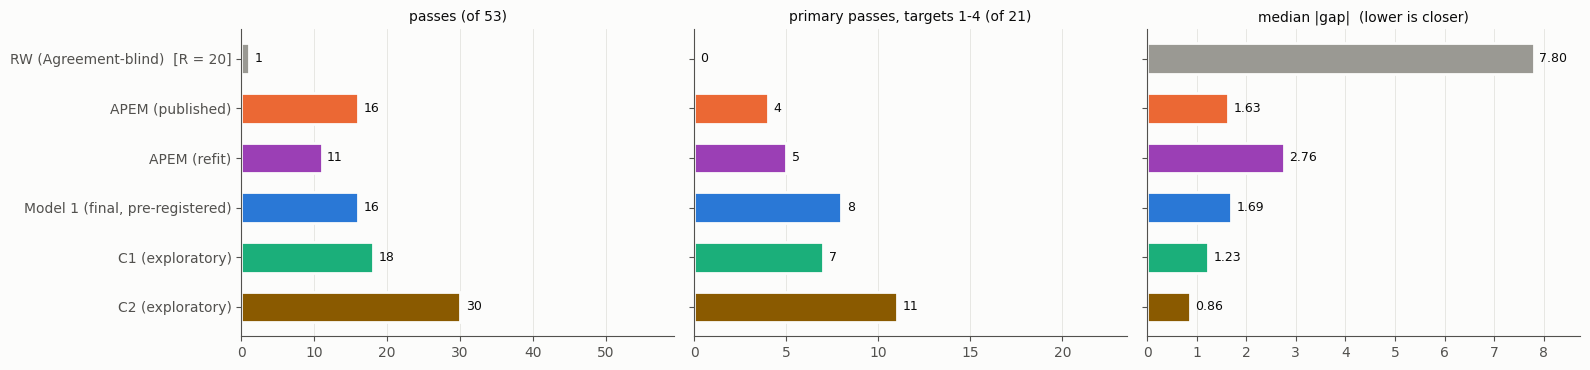

,R,passes (of 53),"primary passes, targets 1-4 (of 21)",median |gap|
RW (Agreement-blind) [R = 20],20.0,1.0,0.0,7.80
APEM (published),100.0,16.0,4.0,1.63
APEM (refit),200.0,11.0,5.0,2.76
"Model 1 (final, pre-registered)",200.0,16.0,8.0,1.69
C1 (exploratory),200.0,18.0,7.0,1.23
C2 (exploratory),200.0,30.0,11.0,0.86


In [5]:
check = chk[chk["in_check_list"]]
score = pd.DataFrame({m: {"R": R[m], "passes (of 53)": int((check.loc[check["preset"] == m, "verdict"] == "pass").sum()),
                          "primary passes, targets 1-4 (of %d)" % (check.loc[(check["preset"] == m) & (check["target"] <= 4)].shape[0]):
                              int((check.loc[(check["preset"] == m) & (check["target"] <= 4), "verdict"] == "pass").sum()),
                          "median |gap|": check.loc[check["preset"] == m, "gap"].abs().median()} for m in MODELS}).T
score.index = [LABEL[m] + (f"  [R = {R[m]}]" if m == "RW" else "") for m in MODELS]
PRIM = score.columns[2]

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, col, top in zip(axes, ["passes (of 53)", PRIM, "median |gap|"], [53, int(PRIM.split("of ")[1].rstrip(")")), None]):
    v = score[col].astype(float).to_numpy()
    y = np.arange(len(MODELS))
    ax.barh(y, v, color=[COL[m] for m in MODELS], height=0.62, edgecolor=SURFACE, linewidth=2)
    for yy, vv in zip(y, v):
        ax.annotate(f"{vv:.2f}" if col == "median |gap|" else f"{vv:.0f}", (vv, yy), xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK)
    ax.set_xlim(0, (top or v.max()) * 1.12)
    ax.set_title(col + ("  (lower is closer)" if col == "median |gap|" else ""), fontsize=10)
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
axes[0].set_yticks(range(len(MODELS)))
axes[0].set_yticklabels(score.index)
axes[0].invert_yaxis()
fig.tight_layout()
fig.savefig(fig_path(1), dpi=150)
plt.show()
score.round(2)

**What it shows.** For each model: how many of the 53 check statistics land inside the human 95% CI, how many of the
primary ones (targets 1-4: success, time to consensus, % fraught, % committed) do, and the median distance from the
human value in CI half-widths (0 = on the human value, 1 = at the CI edge). RW has R = 20 replicates, the others 100-200.

## Fig 2 — headline table per cell

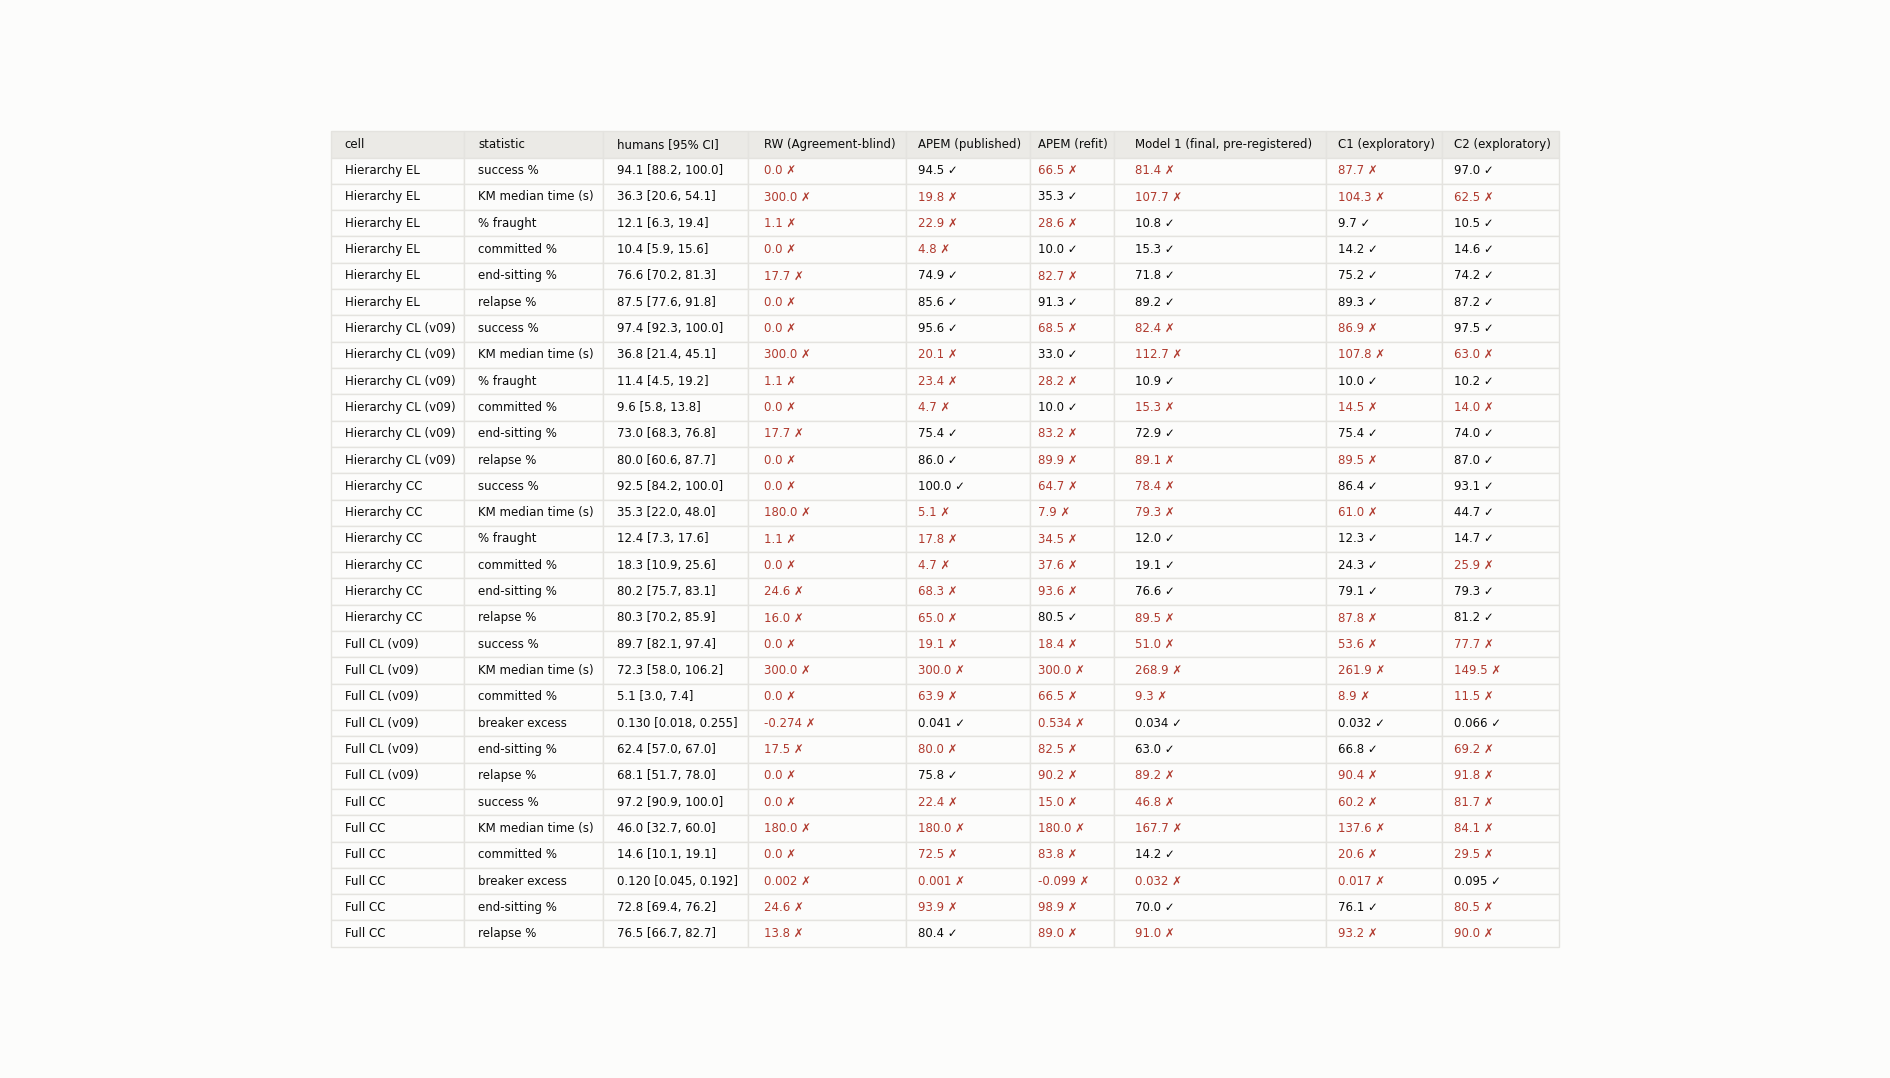

,cell,statistic,human [95% CI],RW,APEM,APEMr,final,C1,C2
0,Hierarchy EL,success %,"94.1 [88.2, 100.0]",0.0 ✗,94.5 ✓,66.5 ✗,81.4 ✗,87.7 ✗,97.0 ✓
1,Hierarchy EL,KM median time (s),"36.3 [20.6, 54.1]",300.0 ✗,19.8 ✗,35.3 ✓,107.7 ✗,104.3 ✗,62.5 ✗
2,Hierarchy EL,% fraught,"12.1 [6.3, 19.4]",1.1 ✗,22.9 ✗,28.6 ✗,10.8 ✓,9.7 ✓,10.5 ✓
3,Hierarchy EL,committed %,"10.4 [5.9, 15.6]",0.0 ✗,4.8 ✗,10.0 ✓,15.3 ✓,14.2 ✓,14.6 ✓
4,Hierarchy EL,end-sitting %,"76.6 [70.2, 81.3]",17.7 ✗,74.9 ✓,82.7 ✗,71.8 ✓,75.2 ✓,74.2 ✓
5,Hierarchy EL,relapse %,"87.5 [77.6, 91.8]",0.0 ✗,85.6 ✓,91.3 ✓,89.2 ✓,89.3 ✓,87.2 ✓
6,Hierarchy CL (v09),success %,"97.4 [92.3, 100.0]",0.0 ✗,95.6 ✓,68.5 ✗,82.4 ✗,86.9 ✗,97.5 ✓
7,Hierarchy CL (v09),KM median time (s),"36.8 [21.4, 45.1]",300.0 ✗,20.1 ✗,33.0 ✓,112.7 ✗,107.8 ✗,63.0 ✗
8,Hierarchy CL (v09),% fraught,"11.4 [4.5, 19.2]",1.1 ✗,23.4 ✗,28.2 ✗,10.9 ✓,10.0 ✓,10.2 ✓
9,Hierarchy CL (v09),committed %,"9.6 [5.8, 13.8]",0.0 ✗,4.7 ✗,10.0 ✓,15.3 ✗,14.5 ✗,14.0 ✗


In [6]:
HEAD = [(1, "success %"), (2, "KM median time (s)"), (3, "% fraught"), (4, "committed %"), (5, "breaker excess"),
        (6, "end-sitting %"), (7, "relapse %")]
fmt = lambda x, small: "—" if pd.isna(x) else (f"{x:.3f}" if small else f"{x:.1f}")
rows = []
for cell in CELLS:
    for t, name in HEAD:
        if (t == 3 and cell[0] != "Hierarchy") or (t == 5 and cell[0] != "Full"):
            continue
        r = wide[(wide["target"] == t) & (wide["stat"] == targets.CHECKS[t]) & (wide["topology"] == cell[0]) &
                 (wide["dataset"] == cell[1])].iloc[0]
        small = t == 5
        row = {"cell": cname(cell), "statistic": name,
               "human [95% CI]": f"{fmt(r['human'], small)} [{fmt(r['ci_lo'], small)}, {fmt(r['ci_hi'], small)}]"}
        for m in MODELS:
            row[m] = f"{fmt(r[f'sim_{m}'], small)} {'✓' if r[f'pass_{m}'] else '✗'}"
        rows.append(row)
headline = pd.DataFrame(rows)
headline.to_csv(config.TABLES / "sup_headline.csv", index=False)

fig, ax = plt.subplots(figsize=(19, 0.34 * (len(headline) + 2)))
ax.axis("off")
cols = ["cell", "statistic", "human [95% CI]"] + MODELS
tab = ax.table(cellText=headline[cols].to_numpy(), colLabels=["cell", "statistic", "humans [95% CI]"] +
               [LABEL[m] for m in MODELS], loc="center", cellLoc="left", colLoc="left")
tab.auto_set_font_size(False)
tab.set_fontsize(8.5)
tab.scale(1, 1.25)
for (i, j), c in tab.get_celld().items():
    c.set_edgecolor(GRID)
    c.set_facecolor(BAND if i == 0 else SURFACE)
    if i > 0 and j >= 3:
        c.get_text().set_color(INK if "✓" in c.get_text().get_text() else "#b03a2e")
tab.auto_set_column_width(list(range(len(cols))))
fig.tight_layout()
fig.savefig(fig_path(2), dpi=150, bbox_inches="tight")
plt.show()
headline

**What it shows.** The outcome targets per cell: the human value with its 95% CI, then each model's mean over its
replicates with ✓ (inside the CI) or ✗ (outside, in red). % fraught exists only on Hierarchy and the breaker excess only
on Full. Saved as `results/tables/sup_headline.csv`.

## Fig 3 — gap dot plot

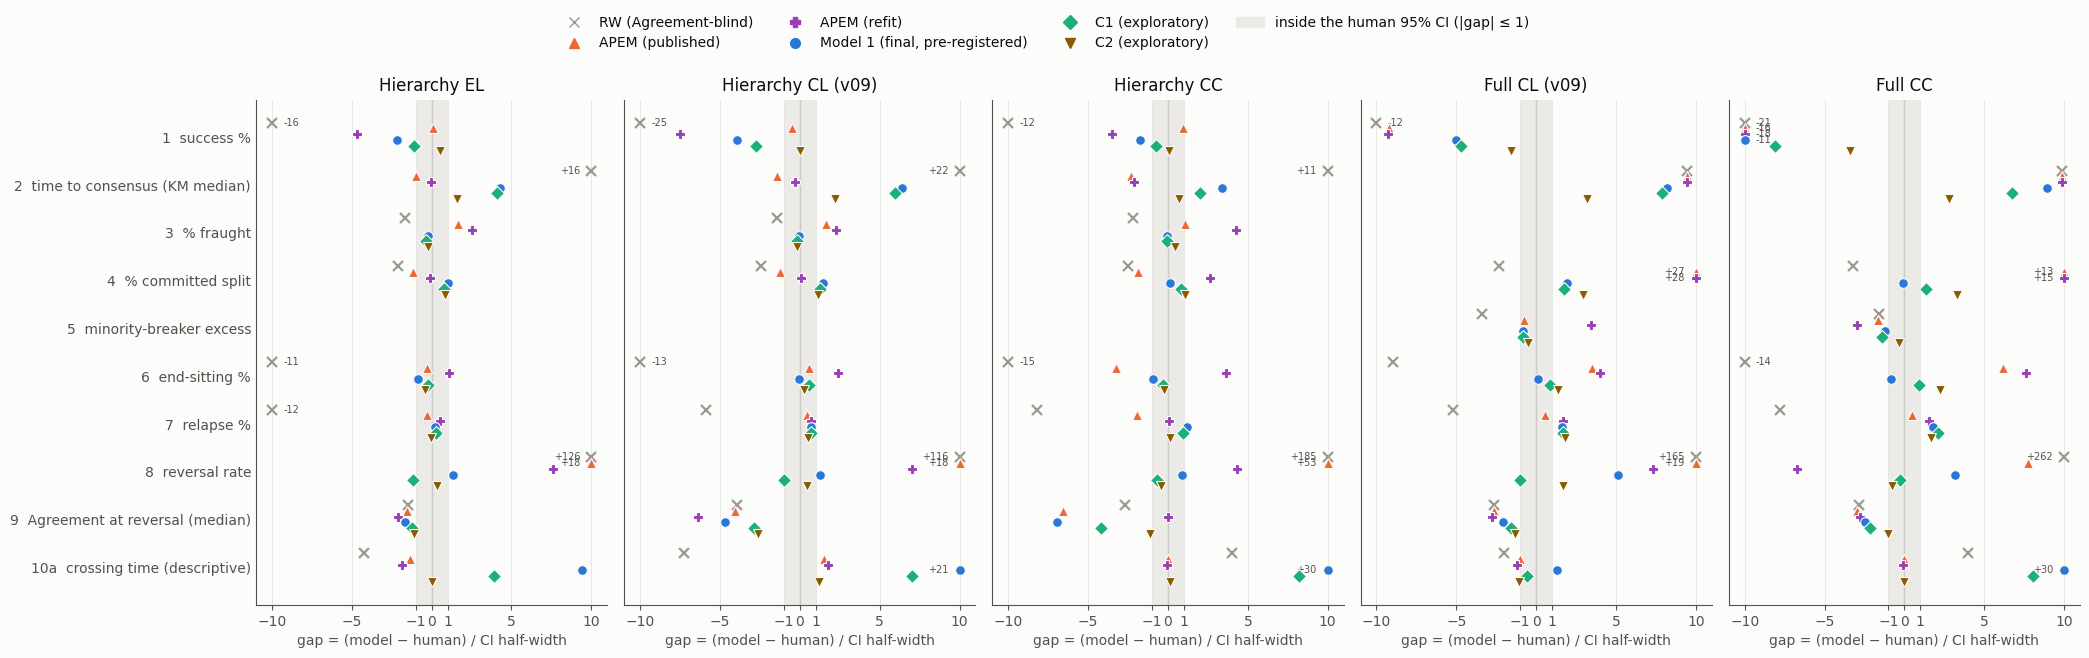

In [7]:
ROWS = [(1, "success_rate_pct", "1  success %"), (2, "consensus_time_km_median_s", "2  time to consensus (KM median)"),
        (3, "fraught_pct_mean", "3  % fraught"), (4, "committed_pct_mean", "4  % committed split"),
        (5, "breaker_excess", "5  minority-breaker excess"), (6, "end_sitting_pct", "6  end-sitting %"),
        (7, "relapse_pct", "7  relapse %"), (8, "reversal_rate", "8  reversal rate"),
        (9, "f_rev_median", "9  Agreement at reversal (median)"),
        (10, "crossing_time_median_s", "10a  crossing time (descriptive)")]
OFF = dict(zip(MODELS, np.linspace(-0.3, 0.3, len(MODELS))))
fig, axes = plt.subplots(1, 5, figsize=(21, 6.6), sharey=True)
for ax, cell in zip(axes, CELLS):
    ax.axvspan(-1, 1, color=BAND, zorder=0, linewidth=0)
    ax.axvline(0, color=INK_2, linewidth=0.8, zorder=1)
    for y, (t, s, _) in enumerate(ROWS):
        r = wide[(wide["target"] == t) & (wide["stat"] == s) & (wide["topology"] == cell[0]) & (wide["dataset"] == cell[1])]
        if len(r) == 0:
            continue
        for m in MODELS:
            g = r[f"gap_{m}"].iloc[0]
            if np.isnan(g):
                continue
            x, yy = float(np.clip(g, -10, 10)), y + OFF[m]
            ax.plot([x], [yy], linestyle="none", marker=MARK[m], markersize=7, color=COL[m],
                    markeredgecolor=COL[m] if m == "RW" else SURFACE, markeredgewidth=1.6 if m == "RW" else 0.8, zorder=3)
            if abs(g) > 10:
                ax.annotate(f"{g:+.0f}", (x, yy), xytext=(-8 if g > 0 else 8, 0), textcoords="offset points",
                            ha="right" if g > 0 else "left", va="center", fontsize=7, color=INK_2)
    ax.set_xlim(-11, 11)
    ax.set_xticks([-10, -5, -1, 0, 1, 5, 10])
    ax.set_title(cname(cell))
    ax.grid(axis="x", color=GRID, linewidth=0.6)
    ax.tick_params(axis="y", length=0)
    ax.set_xlabel("gap = (model − human) / CI half-width")
axes[0].set_yticks(range(len(ROWS)))
axes[0].set_yticklabels([r[2] for r in ROWS])
axes[0].invert_yaxis()
handles = [Line2D([], [], linestyle="none", marker=MARK[m], color=COL[m], markersize=7, label=LABEL[m]) for m in MODELS]
handles.append(Patch(color=BAND, label="inside the human 95% CI (|gap| ≤ 1)"))
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig(fig_path(3), dpi=150)
plt.show()

**What it shows.** One row per target and one marker per model: how far the model's mean sits from the human value, in
human CI half-widths (grey band = inside the CI; right = model higher). Markers beyond ±10 sit at the edge with their
true value printed. 10a (crossing time) is descriptive only: C1 and C2 match it by construction. APEM (refit) is the purple plus.

## Pending runs — APEM (refit) in Figs 4-9

Not run yet. 20 replicates each, with the stored seed pattern (`scripts/sup_runs.py`):

- **Trajectories (Figs 5-9):** replicates 0-19 replayed from the P26 stage-4 streams: batches 0-1 (10 replicates each)
  of each part, job seed [5304, part, batch] (part 0 = lab, mu 0.05; 1 = cloud, mu 0.8), on the P26 part designs. Every
  replicate's statistics must equal its rows in `p26_reps_stage4.parquet` exactly, else the step stops.
  → `results/tables/sup_traj_APEMr.pkl`
- **Time limit × 3 (Fig 4):** 20 replicates per round, new seed 9006 (registered in `sup_runs.py`, after 9001-9005),
  per part [9006, 0] lab / [9006, 1] cloud. → `results/tables/sup_ext_APEMr.parquet`

```bash
conda activate elec573
python scripts/sup_runs.py traj --model APEMr > results/sup_traj_APEMr.log 2>&1
python scripts/sup_runs.py extended --model APEMr --seed 9006 > results/sup_ext_APEMr.log 2>&1
```

Then re-execute this notebook: refit APEM then appears in Figs 4-9 and the summary.

## Fig 4 — time to the human success level

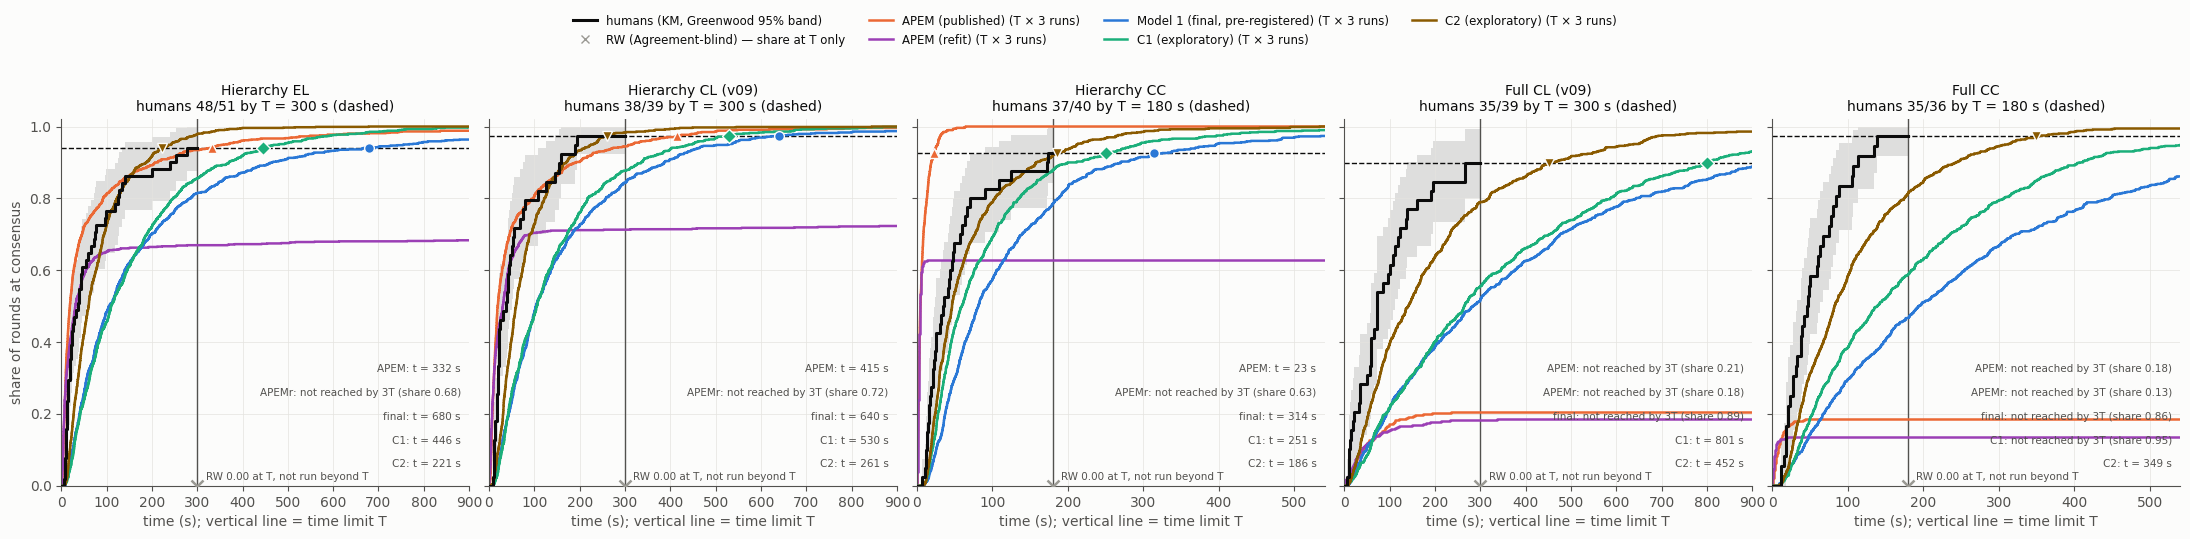

,cell,T (s),humans x/y by T,human time to that level (s),RW share at T,RW time to level (s),RW slowdown,APEM share at T,APEM time to level (s),APEM slowdown,APEMr share at T,APEMr time to level (s),APEMr slowdown,final share at T,final time to level (s),final slowdown,C1 share at T,C1 time to level (s),C1 slowdown,C2 share at T,C2 time to level (s),C2 slowdown
0,Hierarchy EL,300,48/51 (94.1%),276.680,0.0,not run beyond T,NaN,0.934,331.9,1.200,0.670,not reached by 3T (share 0.68),NaN,0.815,679.9,2.457,0.855,446.2,1.613,0.979,221.400,0.800
1,Hierarchy CL (v09),300,38/39 (97.4%),194.450,0.0,not run beyond T,NaN,0.945,415.0,2.134,0.713,not reached by 3T (share 0.72),NaN,0.844,640.1,3.292,0.877,529.6,2.724,0.983,260.700,1.341
2,Hierarchy CC,180,37/40 (92.5%),173.990,0.0,not run beyond T,NaN,1.000,22.508251,0.129,0.628,not reached by 3T (share 0.63),NaN,0.784,313.960396,1.804,0.878,250.891089,1.442,0.919,186.276,1.071
3,Full CL (v09),300,35/39 (89.7%),266.920,0.0,not run beyond T,NaN,0.204,not reached by 3T (share 0.21),NaN,0.183,not reached by 3T (share 0.18),NaN,0.515,not reached by 3T (share 0.89),NaN,0.556,800.9,3.001,0.790,451.700,1.692
4,Full CC,180,35/36 (97.2%),138.302,0.0,not run beyond T,NaN,0.185,not reached by 3T (share 0.18),NaN,0.135,not reached by 3T (share 0.13),NaN,0.467,not reached by 3T (share 0.86),NaN,0.588,not reached by 3T (share 0.95),NaN,0.814,349.175,2.525


In [8]:
def first_time(times, share, level):
    # earliest time a step curve (times sorted, share after each) reaches level, NaN if never
    i = np.flatnonzero(share >= level - 1e-9)
    return times[i[0]] if len(i) else np.nan


rows, curves = [], {}
for cell in CELLS:
    T = config.TIME_LIMIT["cloud" if cell[1] == "CC" else "lab"]
    d = hum["km"][(hum["km"]["topology"] == cell[0]) & (hum["km"]["dataset"] == cell[1])]
    km, _ = V.km_band(d["ttc"], d["event"])
    x, n = int(d["event"].sum()), len(d)
    level = x / n
    t_h = first_time(km["time"].to_numpy(), 1 - km["survival"].to_numpy(), level)
    row = {"cell": cname(cell), "T (s)": T, "humans x/y by T": f"{x}/{n} ({100 * level:.1f}%)",
           "human time to that level (s)": t_h}
    curves[cell] = {"km": km, "T": T, "level": level, "x": x, "n": n, "t_h": t_h}
    for m in PENDING:
        row[f"{m} share at T"], row[f"{m} time to level (s)"], row[f"{m} slowdown"] = "pending", "pending", np.nan
    for m in TM:
        if m not in ext:                                      # RW: no extended run; share at T from its 20 replicates
            k = sim[m]["km"]
            k = k[(k["topology"] == cell[0]) & (k["dataset"] == cell[1])]
            row[f"{m} share at T"] = k["event"].mean()
            row[f"{m} time to level (s)"], row[f"{m} slowdown"] = "not run beyond T", np.nan
            curves[cell][m] = {"at_T": k["event"].mean()}
            continue
        e = ext[m][(ext[m]["topology"] == cell[0]) & (ext[m]["dataset"] == cell[1])]
        tt = np.sort(e.loc[e["success"], "end_time"].to_numpy())
        share = np.arange(1, len(tt) + 1) / len(e)
        t_m = first_time(tt, share, level)
        at_T = np.mean(e["success"] & (e["end_time"] <= T))
        row[f"{m} share at T"] = at_T
        row[f"{m} time to level (s)"] = t_m if not np.isnan(t_m) else f"not reached by 3T (share {share[-1] if len(tt) else 0:.2f})"
        row[f"{m} slowdown"] = t_m / t_h if not np.isnan(t_m) else np.nan
        curves[cell][m] = {"t": tt, "share": share, "at_T": at_T, "t_m": t_m, "end": share[-1] if len(tt) else 0.0}
    rows.append(row)
reach = pd.DataFrame(rows)
reach.to_csv(config.TABLES / "sup_time_to_level.csv", index=False)

fig, axes = plt.subplots(1, 5, figsize=(22, 5.4), sharey=True)
for ax, cell in zip(axes, CELLS):
    c = curves[cell]
    T, km = c["T"], c["km"]
    tt = np.r_[0, km["time"]]
    ax.step(tt, 1 - np.r_[1, km["survival"]], where="post", color=COL["humans"], linewidth=2.2, zorder=4)
    ax.fill_between(tt, 1 - np.r_[1, km["hi"]], 1 - np.r_[1, km["lo"]], step="post", color=INK, alpha=0.12, linewidth=0)
    ax.axhline(c["level"], color=INK, linestyle="--", linewidth=1)
    ax.axvline(T, color=INK_2, linewidth=1)
    for k, m in enumerate(TM):
        q = c[m]
        if "t" not in q:
            ax.plot([T], [q["at_T"]], marker=MARK[m], color=COL[m], markersize=8, markeredgewidth=1.8, zorder=5)
            ax.annotate(f"RW {q['at_T']:.2f} at T, not run beyond T", (T, q["at_T"]), xytext=(6, 4 + 0 * k),
                        textcoords="offset points", fontsize=7.5, color=INK_2)
            continue
        ax.step(np.r_[0, q["t"], 3 * T], np.r_[0, q["share"], q["end"]], where="post", color=COL[m], linewidth=1.8)
        if not np.isnan(q["t_m"]):
            ax.plot([q["t_m"]], [c["level"]], marker=MARK[m], color=COL[m], markersize=7, markeredgecolor=SURFACE, zorder=6)
            label = f"t = {q['t_m']:.0f} s"
        else:
            label = f"not reached by 3T (share {q['end']:.2f})"
        ax.annotate(f"{m}: {label}", (0.98, 0.05 + 0.065 * (len(TM) - 1 - k)), xycoords="axes fraction", ha="right",
                    fontsize=7.5, color=INK_2)
    ax.set_xlim(0, 3 * T)
    ax.set_ylim(0, 1.02)
    ax.set_title(f"{cname(cell)}\nhumans {c['x']}/{c['n']} by T = {T} s (dashed)", fontsize=10)
    ax.set_xlabel("time (s); vertical line = time limit T")
    ax.grid(color=GRID, linewidth=0.5)
axes[0].set_ylabel("share of rounds at consensus")
handles = [Line2D([], [], color=INK, linewidth=2.2, label="humans (KM, Greenwood 95% band)")]
handles += [Line2D([], [], color=COL[m], linewidth=1.8, marker=MARK[m] if m == "RW" else None,
                   linestyle="none" if m == "RW" else "-", label=LABEL[m] + (" — share at T only" if m == "RW" else " (T × 3 runs)"))
            for m in TM]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.88))
fig.savefig(fig_path(4), dpi=150)
plt.show()
reach.round(3)

**What it shows.** The share of rounds that have reached consensus by time t. Humans stop at the time limit T (their
Greenwood band shaded); the models ran to 3T, so their curves show how long they need to reach the share humans
reach by T (dashed line). The table gives each model's time to that level and the slowdown factor against the human
time to the same level; RW was not run beyond T, so only its share at T is shown.

## Fig 5 — averaged normalized trajectories (Tabor et al. Fig. 4/5 style; CL v09)

RW qualifying runs: {'Hierarchy CL (v09)': 0, 'Full CL (v09)': 0} -> not shown (< 20)


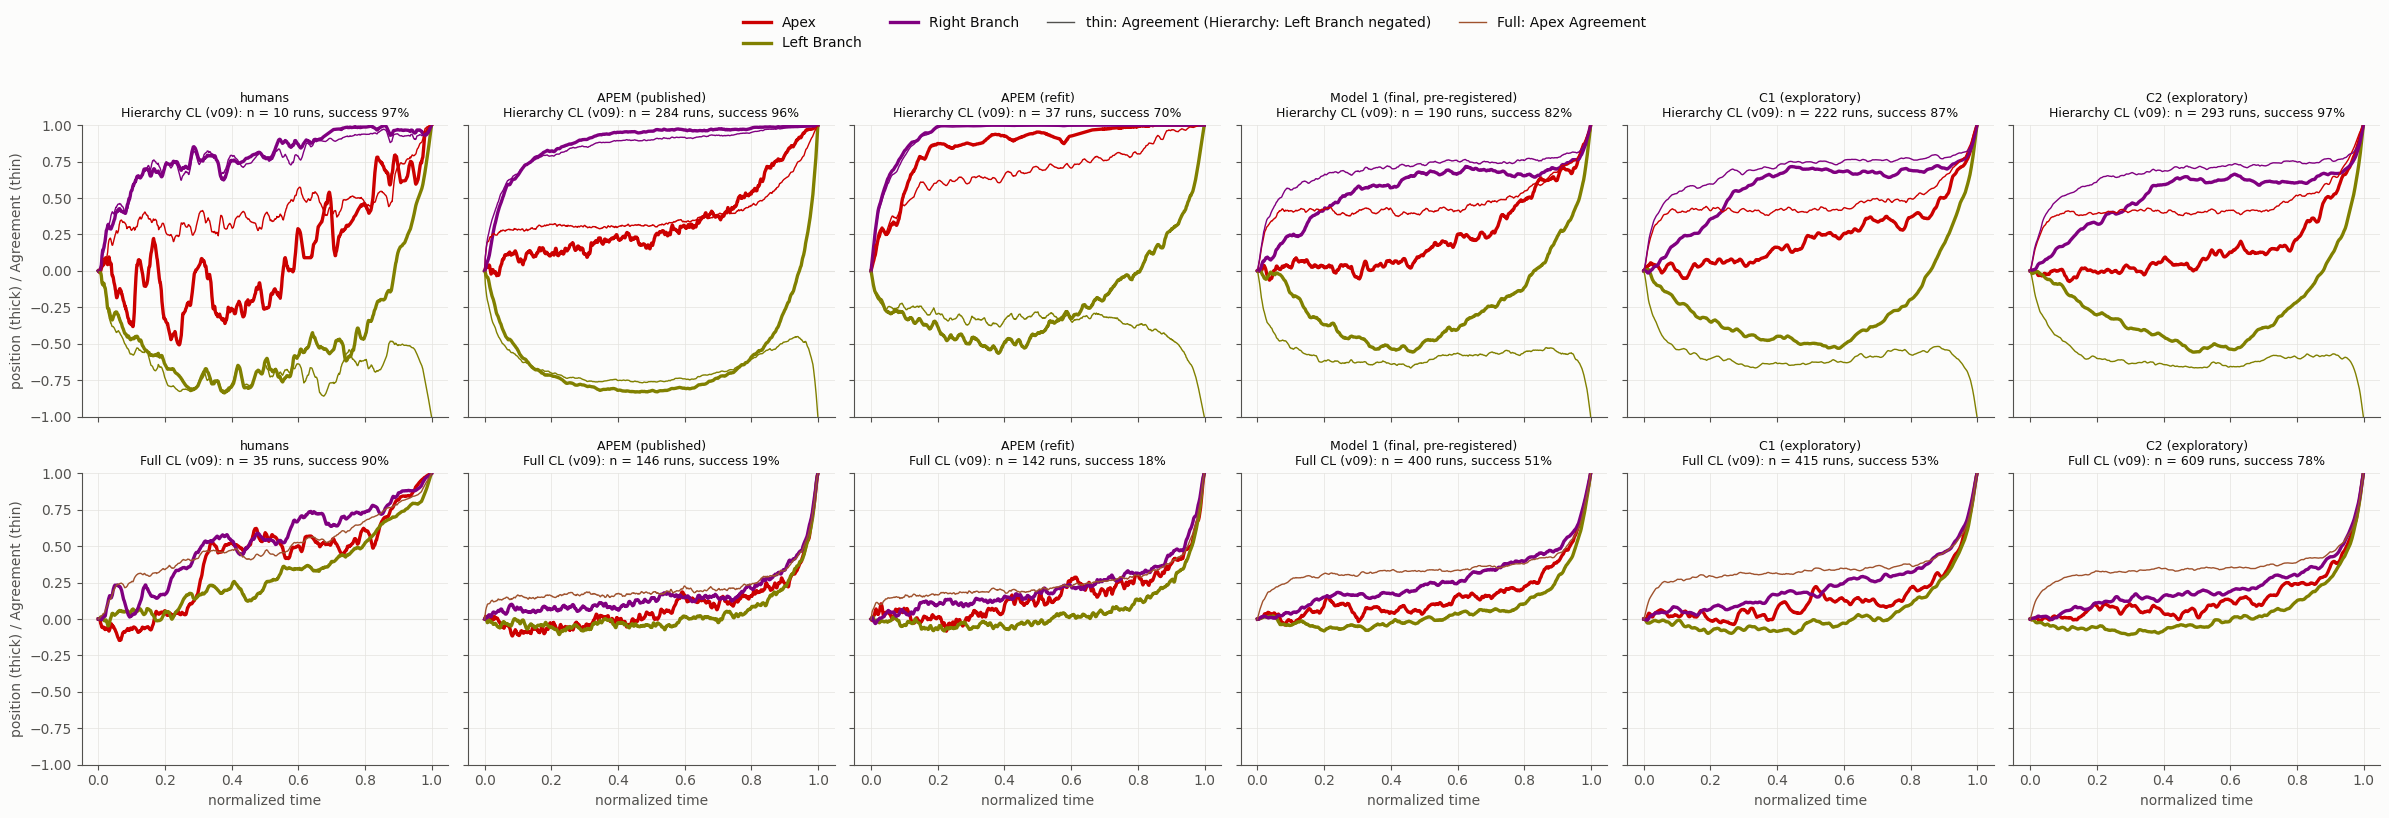

In [9]:
rw_n = {c: sim["RW"]["traj"].get(c, [0, 0, 0])[2] for c in sup.CL_CELLS}
show_rw = all(n >= 20 for n in rw_n.values())
cols5 = ["humans", "APEM"] + (["APEMr"] if "APEMr" in TM else []) + ["final", "C1", "C2"] + (["RW"] if show_rw else [])
print("RW qualifying runs:", {cname(c): n for c, n in rw_n.items()}, "->", "shown" if show_rw else "not shown (< 20)")
src = {"humans": hum, **sim}
tvals = np.arange(V.NWARP + 1) / (V.NWARP + 1)
fig, axes = plt.subplots(2, len(cols5), figsize=(4 * len(cols5), 8.2), sharex=True, sharey=True)
for i, top in enumerate(["Hierarchy", "Full"]):
    cell = (top, "CL")
    for j, name in enumerate(cols5):
        ax = axes[i, j]
        x_sum, a_sum, n = src[name]["traj"].get(cell, [None, None, 0])
        k = src[name]["km"]
        succ = k.loc[(k["topology"] == top) & (k["dataset"] == "CL"), "event"].mean()
        ax.axhline(0, color=GRID, linewidth=0.8)
        if n > 0:
            gm, am = V.group_means(x_sum / n), V.group_means(a_sum / n)
            for kk, colour in enumerate(BRANCH.values()):
                ax.plot(tvals, gm[:, kk], color=colour, linewidth=2.4)
            if top == "Hierarchy":
                am[:, 1] = -am[:, 1]                                   # runapem.m: Left Branch Agreement negated
                for kk, colour in enumerate(BRANCH.values()):
                    ax.plot(tvals, am[:, kk], color=colour, linewidth=1)
            else:
                ax.plot(tvals, am[:, 0], color=SIENNA, linewidth=1)    # Full: Apex Agreement only
        ax.set_title(f"{LABEL[name]}\n{cname(cell)}: n = {n} runs, success {100 * succ:.0f}%", fontsize=9)
        ax.set_ylim(-1, 1)
        ax.grid(color=GRID, linewidth=0.5)
    axes[i, 0].set_ylabel("position (thick) / Agreement (thin)")
for ax in axes[1]:
    ax.set_xlabel("normalized time")
handles = [Line2D([], [], color=c, linewidth=2.4, label=l) for l, c in BRANCH.items()]
handles += [Line2D([], [], color=INK_2, linewidth=1, label="thin: Agreement (Hierarchy: Left Branch negated)"),
            Line2D([], [], color=SIENNA, linewidth=1, label="Full: Apex Agreement")]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.91))
fig.savefig(fig_path(5), dpi=150)
plt.show()

**What it shows.** The paper's averaging: every qualifying round stretched to the same length (0 = start, 1 = consensus),
flipped so the winner is +1, then averaged. Thick lines are the mean positions of the Apex and the two branches (the Left
Branch is the one that switches); thin lines are their Agreement. Each title gives n (qualifying runs over 20 replicates)
and the cell's success rate in those replicates. RW is left out if it has fewer than 20 qualifying runs (printed above).

## Fig 6 — Agreement at reversal

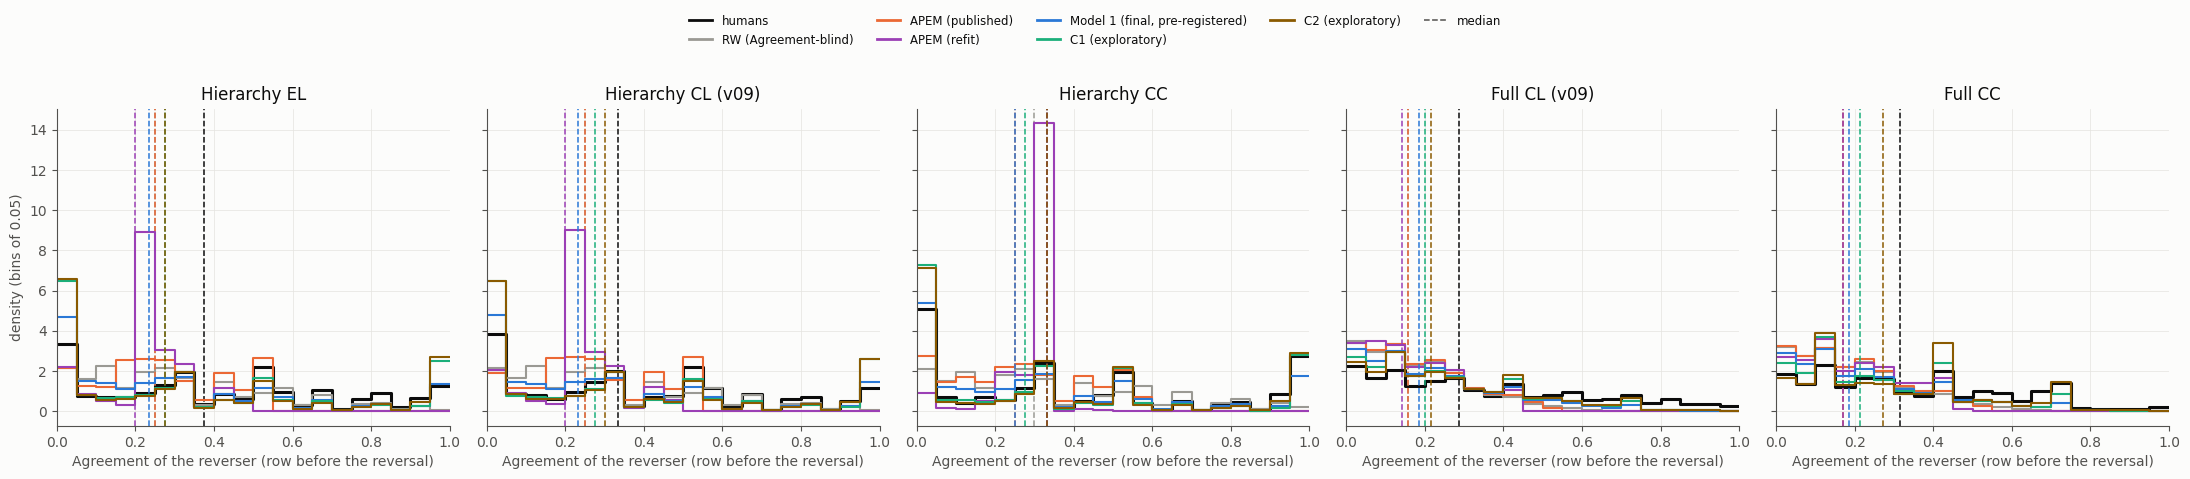

,humans,RW,APEM,APEMr,final,C1,C2
Full CC,0.314,0.171,0.171,0.171,0.186,0.214,0.271
Full CL (v09),0.286,0.157,0.157,0.143,0.186,0.200,0.214
Hierarchy CC,0.333,0.300,0.250,0.333,0.250,0.275,0.333
Hierarchy CL (v09),0.333,0.250,0.250,0.200,0.233,0.275,0.300
Hierarchy EL,0.375,0.250,0.250,0.200,0.233,0.275,0.275


In [10]:
def wmedian(v, n):
    # median of the values v repeated n times (np.percentile's 50%: mean of the two middle values)
    o = np.argsort(v)
    v, c = np.asarray(v, float)[o], np.cumsum(np.asarray(n)[o])
    N = c[-1]
    lo, hi = v[np.searchsorted(c, (N - 1) // 2 + 1)], v[np.searchsorted(c, N // 2 + 1)]
    return (lo + hi) / 2


bins = np.linspace(0, 1, 21)
med = {}
fig, axes = plt.subplots(1, 5, figsize=(22, 4.8), sharey=True)
for ax, cell in zip(axes, CELLS):
    for name in ["humans"] + TM:
        r = src[name]["rev"]
        r = r[(r["topology"] == cell[0]) & (r["dataset"] == cell[1])]
        dens, _ = np.histogram(r["A"], bins=bins, weights=r["n"], density=True)
        ax.step(bins, np.r_[dens, dens[-1]], where="post", color=COL[name], linewidth=2.2 if name == "humans" else 1.5)
        med[(cname(cell), name)] = wmedian(r["A"].to_numpy(), r["n"].to_numpy())
        ax.axvline(med[(cname(cell), name)], color=COL[name], linestyle="--", linewidth=1.1)
    ax.set_title(cname(cell))
    ax.set_xlabel("Agreement of the reverser (row before the reversal)")
    ax.set_xlim(0, 1)
    ax.grid(color=GRID, linewidth=0.5)
axes[0].set_ylabel("density (bins of 0.05)")
handles = [Line2D([], [], color=COL[m], linewidth=2, label=LABEL[m]) for m in ["humans"] + TM]
handles += [Line2D([], [], color=INK_2, linewidth=1.1, linestyle="--", label="median")]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.savefig(fig_path(6), dpi=150)
plt.show()
medians = pd.Series(med).unstack()[["humans"] + TM]
h9 = wide[wide["target"] == 9]
h9 = h9.set_index(h9["topology"] + " " + h9["dataset"])["human"]
assert np.allclose([medians.loc[cname(c), "humans"] for c in CELLS], [h9[f"{c[0]} {c[1]}"] for c in CELLS])   # = target 9
medians.round(3)

**What it shows.** For every reversal, the reverser's Agreement in the row before it (0 = its neighbourhood is split, 1 =
all at its own end), as a density per cell, with medians dashed (the human medians equal target 9). Mass to the left
means reversals happen under disagreement; RW, which ignores Agreement, shows where reversals land with no Agreement
dependence at all. Model curves pool 20 replicates.

## Fig 7 — Full standoffs: who breaks them

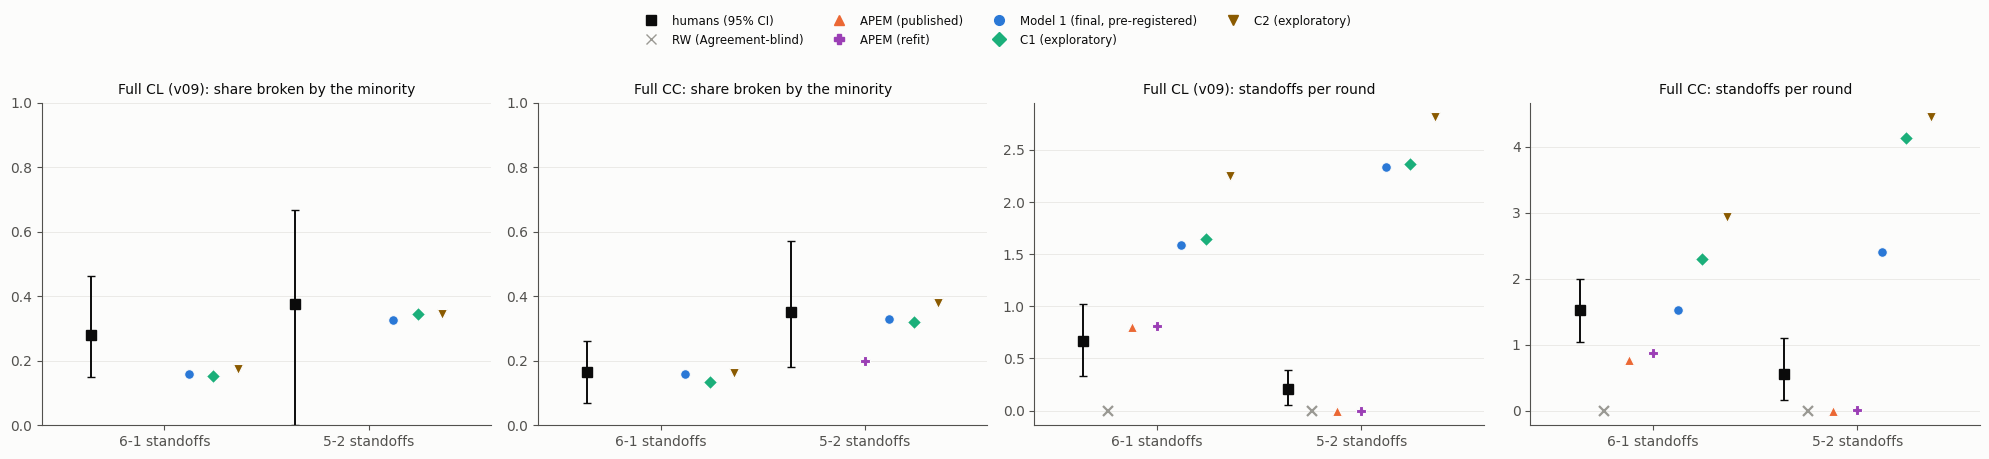

standoffs                                  break by minority                                            per round                                    
who                    humans RW APEM APEMr final    C1    C2             humans   RW APEM APEMr final    C1    C2             humans    RW  APEM APEMr final    C1    C2
cell          split                                                                                                                                                      
Full CC       5-2          20  0    0     5  1727  2978  3201  0.35 [0.18, 0.57]  nan  nan  0.20  0.33  0.32  0.38  0.56 [0.16, 1.11]  0.00  0.00  0.01  2.40  4.14  4.45
              6-1          55  0  556   629  1093  1660  2118  0.16 [0.07, 0.26]  nan  nan   nan  0.16  0.13  0.16  1.53 [1.03, 2.00]  0.00  0.77  0.87  1.52  2.31  2.94
Full CL (v09) 5-2           8  0    0     0  1823  1846  2192  0.38 [0.00, 0.67]  nan  nan   nan  0.33  0.34  0.34  0.21 [0.05, 0.38]  0.00  0.00  0.00  2.34  2.37  2.81
              6-1          26  0  625   634  1238  1280  1757  0.28 [0.15, 0.46]  nan  nan   nan  0.16  0.15  0.18  0.67 [0.33, 1.03]  0.00  0.80  0.81  1.59  1.64  2.25

In [11]:
def boot(d, rounds, fn, n_boot=1000, seed=config.SEED):
    # fn(rows, n_rounds) with 95% CIs: n_boot resamples of the cell's files (rng(seed)). {stat: (value, lo, hi)}
    d = d.reset_index(drop=True)
    files = rounds["file"].unique()
    per_file = rounds.groupby("file").size()
    by_file = {f: idx.to_numpy() for f, idx in d.groupby("file").groups.items()}
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(n_boot):
        draw = files[rng.integers(0, len(files), len(files))]
        rows = np.concatenate([by_file.get(f, np.array([], dtype=int)) for f in draw])
        vals.append(fn(d.loc[rows], per_file[draw].sum()))
    vals = pd.DataFrame(vals)
    return {k: (v, *np.nanpercentile(vals[k].to_numpy(float), [2.5, 97.5])) for k, v in fn(d, len(rounds)).items()}


so_stats = lambda d, n: {"per_round": len(d) / n, "break_min_share": d["break_minority"].mean()}
FULL = [c for c in CELLS if c[0] == "Full"]
so = []
for cell in FULL:
    for split in ["6-1", "5-2"]:
        for name in ["humans"] + TM:
            s, r = src[name]["standoffs"], src[name]["rounds5"]
            s = s[(s["dataset"] == cell[1]) & (s["split"] == split)]
            r = r[(r["topology"] == "Full") & (r["dataset"] == cell[1])]
            row = {"cell": cname(cell), "split": split, "who": name, "standoffs": len(s)}
            if name == "humans":
                for k, (v, lo, hi) in boot(s, r, so_stats).items():
                    row.update({k: v, f"{k}_lo": lo, f"{k}_hi": hi})
            else:
                row.update(so_stats(s, len(r)))
            so.append(row)
so = pd.DataFrame(so)

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
panels = [(c, s) for c in FULL for s in ["6-1", "5-2"]]
for stat, axs, lab in [("break_min_share", axes[:2], "share broken by the minority"), ("per_round", axes[2:], "standoffs per round")]:
    for ax, cell in zip(axs, FULL):
        for i, split in enumerate(["6-1", "5-2"]):
            for j, name in enumerate(["humans"] + TM):
                q = so[(so["cell"] == cname(cell)) & (so["split"] == split) & (so["who"] == name)].iloc[0]
                x = i + (j - len(TM) / 2) * 0.12
                if name == "humans":
                    ax.errorbar([x], [q[stat]], yerr=[[q[stat] - q[f"{stat}_lo"]], [q[f"{stat}_hi"] - q[stat]]],
                                color=INK, marker=MARK[name], markersize=7, capsize=3, linewidth=1.4)
                else:
                    ax.plot([x], [q[stat]], marker=MARK[name], color=COL[name], markersize=7, linestyle="none",
                            markeredgecolor=COL[name] if name == "RW" else SURFACE, markeredgewidth=1.6 if name == "RW" else 0.8)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["6-1 standoffs", "5-2 standoffs"])
        ax.set_xlim(-0.6, 1.6)
        ax.set_title(f"{cname(cell)}: {lab}", fontsize=10)
        ax.grid(axis="y", color=GRID, linewidth=0.5)
        if stat == "break_min_share":
            ax.set_ylim(0, 1)
handles = [Line2D([], [], color=COL[m], marker=MARK[m], linestyle="none", markersize=7,
                  label=LABEL[m] + (" (95% CI)" if m == "humans" else "")) for m in ["humans"] + TM]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.86))
fig.savefig(fig_path(7), dpi=150)
plt.show()
view = so.copy()
view["break by minority"] = [f"{r.break_min_share:.2f}" + (f" [{r.break_min_share_lo:.2f}, {r.break_min_share_hi:.2f}]"
                             if r.who == "humans" else "") for r in so.itertuples()]
view["per round"] = [f"{r.per_round:.2f}" + (f" [{r.per_round_lo:.2f}, {r.per_round_hi:.2f}]" if r.who == "humans" else "")
                     for r in so.itertuples()]
view.pivot(index=["cell", "split"], columns="who", values=["standoffs", "break by minority", "per round"])[
    [(s, w) for s in ["standoffs", "break by minority", "per round"] for w in ["humans"] + TM]]

**What it shows.** A standoff is all 7 players at a wall in a 6-1 or 5-2 split for at least 0.5 s (`standoffs.py`).
Left: the share of standoffs that the minority side breaks (humans with 95% CI); right: how many standoffs a round has.
A model can match who breaks while having far more standoffs than people, or the reverse. RW never has all 7 at a wall
and APEM (published) has no 5-2 standoffs, so they have no break share.

## Fig 8 — stuck episodes by type

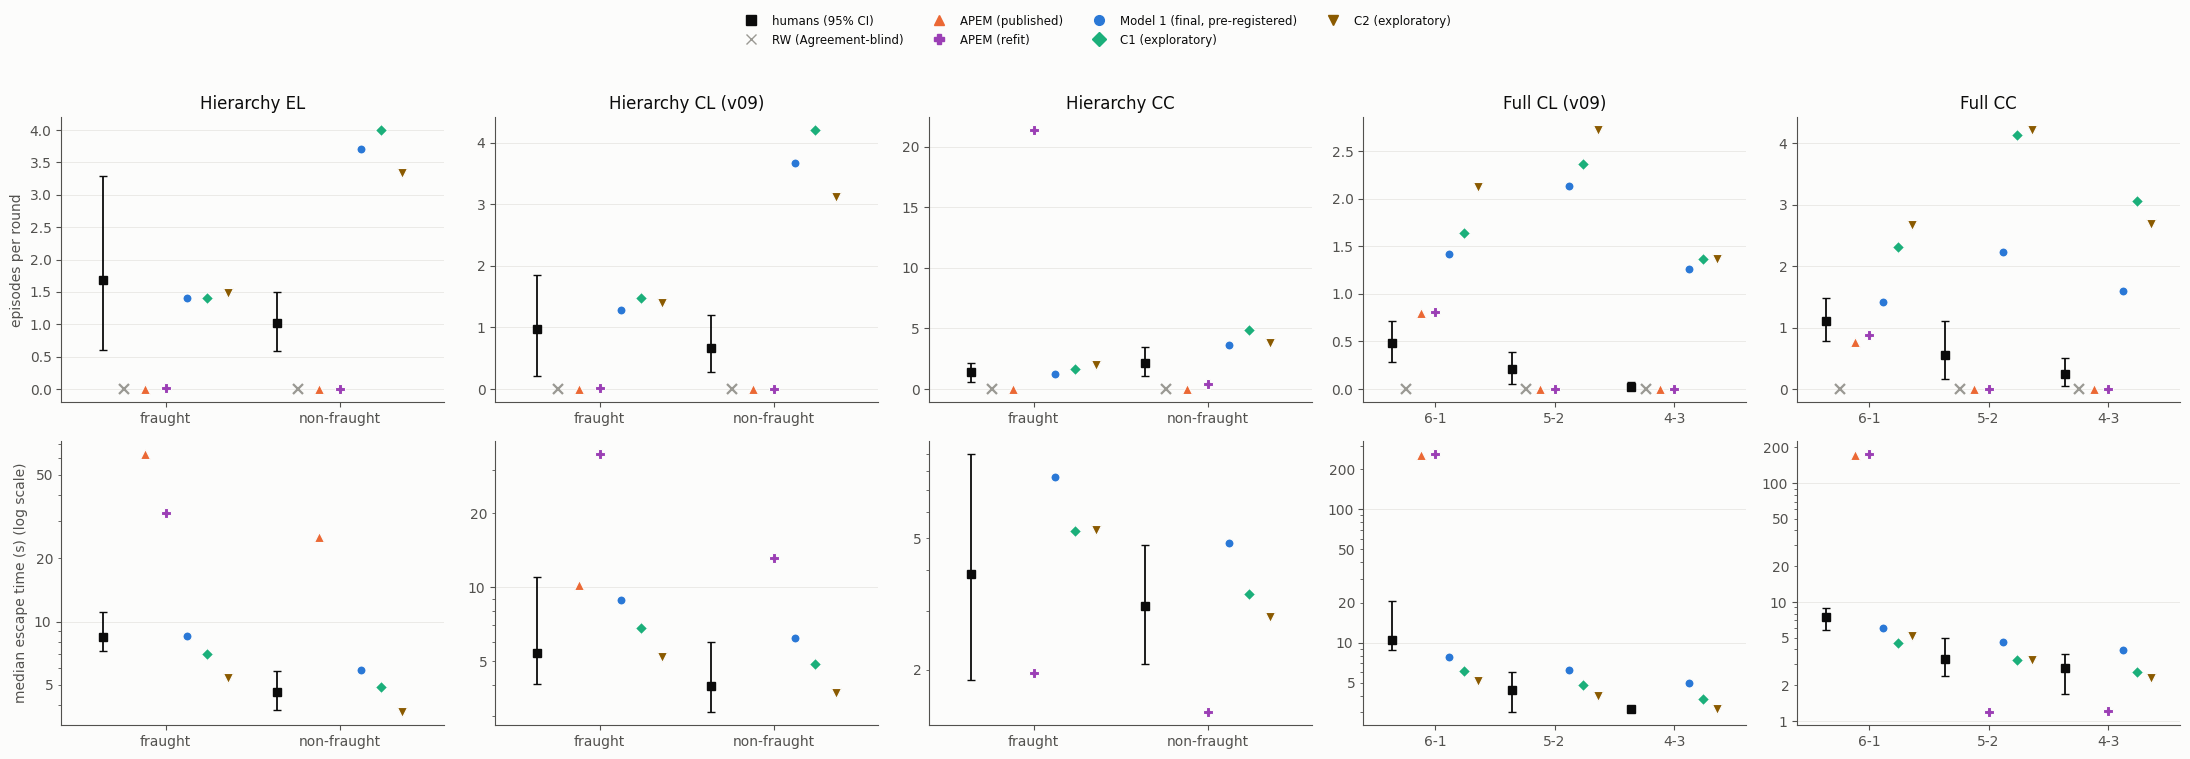

episodes                                           per round                                      median escape (s)                                 
who                              humans RW APEM  APEMr final    C1    C2             humans    RW  APEM  APEMr final    C1    C2            humans RW   APEM  APEMr final   C1   C2
cell               type                                                                                                                                                            
Hierarchy EL       fraught           86  0    1     12  1440  1437  1511  1.69 [0.61, 3.29]  0.00  0.00   0.01  1.41  1.41  1.48   8.4 [7.2, 11.1]  —   63.1   33.0   8.5  7.0  5.4
                   non-fraught       52  0    1      0  3784  4076  3406  1.02 [0.59, 1.49]  0.00  0.00   0.00  3.71  4.00  3.34    4.6 [3.8, 5.8]  —   25.4      —   5.9  4.9  3.7
Hierarchy CL (v09) fraught           38  0    3     11  1007  1153  1092  0.97 [0.21, 1.85]  0.00  0.00   0.01  1.29  1.48  1.40   5.4 [4.1, 11.0]  —   10.2   35.0   8.9  6.8  5.2
                   non-fraught       26  0    0      1  2869  3278  2429  0.67 [0.28, 1.21]  0.00  0.00   0.00  3.68  4.20  3.11    3.9 [3.1, 6.0]  —      —   13.2   6.2  4.9  3.7
Hierarchy CC       fraught           55  0    0  17081  1006  1348  1578  1.38 [0.62, 2.14]  0.00  0.00  21.35  1.26  1.69  1.97    3.9 [1.9, 9.0]  —      —    1.9   7.7  5.2  5.3
                   non-fraught       86  0    0    306  2919  3884  3038  2.15 [1.11, 3.49]  0.00  0.00   0.38  3.65  4.86  3.80    3.1 [2.1, 4.8]  —      —    1.5   4.9  3.4  2.9
Full CL (v09)      6-1               19  0  625    634  1108  1280  1654  0.49 [0.28, 0.72]  0.00  0.80   0.81  1.42  1.64  2.12  10.5 [8.8, 20.6]  —  257.2  262.1   7.8  6.2  5.2
                   5-2                8  0    0      0  1666  1846  2121  0.21 [0.05, 0.38]  0.00  0.00   0.00  2.14  2.37  2.72    4.4 [3.0, 6.0]  —      —      —   6.2  4.8  4.0
                   4-3                1  0    0      0   986  1064  1068  0.03 [0.00, 0.08]  0.00  0.00   0.00  1.26  1.36  1.37    3.2 [3.2, 3.2]  —      —      —   5.0  3.8  3.2
Full CC            6-1               40  0  556    629  1017  1660  1924  1.11 [0.77, 1.49]  0.00  0.77   0.87  1.41  2.31  2.67    7.4 [5.9, 9.0]  —  171.4  176.9   6.1  4.5  5.1
                   5-2               20  0    0      5  1603  2978  3032  0.56 [0.16, 1.11]  0.00  0.00   0.01  2.23  4.14  4.21    3.3 [2.4, 5.0]  —      —    1.2   4.7  3.3  3.3
                   4-3                9  0    0      5  1146  2200  1936  0.25 [0.06, 0.50]  0.00  0.00   0.01  1.59  3.06  2.69    2.8 [1.7, 3.7]  —      —    1.2   4.0  2.6  2.3

In [12]:
warnings.filterwarnings("ignore", message="Mean of empty slice")
ep = []
for cell in CELLS:
    for kind in stuck.TYPES[cell[0]]:
        for name in ["humans"] + TM:
            e, r = src[name]["episodes"], src[name]["rounds5"]
            e = e[(e["topology"] == cell[0]) & (e["dataset"] == cell[1]) & (e["type"] == kind)]
            r = r[(r["topology"] == cell[0]) & (r["dataset"] == cell[1])]
            row = {"cell": cname(cell), "type": kind, "who": name, "episodes": len(e)}
            if name == "humans":
                for k, (v, lo, hi) in stuck.boot_cell(e, r.assign(dataset=cell[1])).items():
                    row.update({k: v, f"{k}_lo": lo, f"{k}_hi": hi})
            else:
                row.update(stuck.episode_stats(e, len(r)))
            ep.append(row)
ep = pd.DataFrame(ep)

fig, axes = plt.subplots(2, 5, figsize=(22, 7.6))
for col, cell in enumerate(CELLS):
    kinds = stuck.TYPES[cell[0]]
    for rr, (stat, lab) in enumerate([("per_round", "episodes per round"), ("duration_median", "median escape time (s)")]):
        ax = axes[rr, col]
        for i, kind in enumerate(kinds):
            for j, name in enumerate(["humans"] + TM):
                q = ep[(ep["cell"] == cname(cell)) & (ep["type"] == kind) & (ep["who"] == name)].iloc[0]
                x = i + (j - len(TM) / 2) * 0.12
                if name == "humans":
                    if not np.isnan(q[stat]):
                        ax.errorbar([x], [q[stat]], yerr=[[q[stat] - q[f"{stat}_lo"]], [q[f"{stat}_hi"] - q[stat]]],
                                    color=INK, marker=MARK[name], markersize=6, capsize=3, linewidth=1.3)
                elif not np.isnan(q[stat]):
                    ax.plot([x], [q[stat]], marker=MARK[name], color=COL[name], markersize=6.5, linestyle="none",
                            markeredgecolor=COL[name] if name == "RW" else SURFACE, markeredgewidth=1.6 if name == "RW" else 0.8)
        ax.set_xticks(range(len(kinds)))
        ax.set_xticklabels(kinds)
        ax.set_xlim(-0.6, len(kinds) - 0.4)
        ax.grid(axis="y", color=GRID, linewidth=0.5)
        if rr == 0:
            ax.set_title(cname(cell))
        if col == 0:
            ax.set_ylabel(lab + (" (log scale)" if rr == 1 else ""))
        if rr == 1:
            ax.set_yscale("log")
            ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
            ax.yaxis.set_minor_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}" if str(v)[0] in "25" else ""))
handles = [Line2D([], [], color=COL[m], marker=MARK[m], linestyle="none", markersize=7,
                  label=LABEL[m] + (" (95% CI)" if m == "humans" else "")) for m in ["humans"] + TM]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5, 1.0), fontsize=8.5)
fig.tight_layout(rect=(0, 0, 1, 0.90))
fig.savefig(fig_path(8), dpi=150)
plt.show()
fmt8 = lambda r, s, dec: ("—" if np.isnan(r[s]) else f"{r[s]:.{dec}f}") + (
    f" [{r[s + '_lo']:.{dec}f}, {r[s + '_hi']:.{dec}f}]" if r["who"] == "humans" and not np.isnan(r[s]) else "")
view = ep.assign(**{"per round": [fmt8(r, "per_round", 2) for _, r in ep.iterrows()],
                    "median escape (s)": [fmt8(r, "duration_median", 1) for _, r in ep.iterrows()]})
view.pivot(index=["cell", "type"], columns="who", values=["episodes", "per round", "median escape (s)"])[
    [(s, w) for s in ["episodes", "per round", "median escape (s)"] for w in ["humans"] + TM]].reindex(
    [(cname(c), k) for c in CELLS for k in stuck.TYPES[c[0]]])

**What it shows.** A stuck episode is all 7 players at a wall, not at consensus, for at least 0.5 s (`stuck.py`); it ends
when a player reaches the opposite wall or the round ends. Top: episodes per round by type (Full: the split; Hierarchy:
fraught or not at the corner); bottom: the median escape time (log scale). Humans with 95% CIs; models pool 20 replicates. Star CC is
left out (scorecard only).

## Fig 9 — example rounds (CL v09)

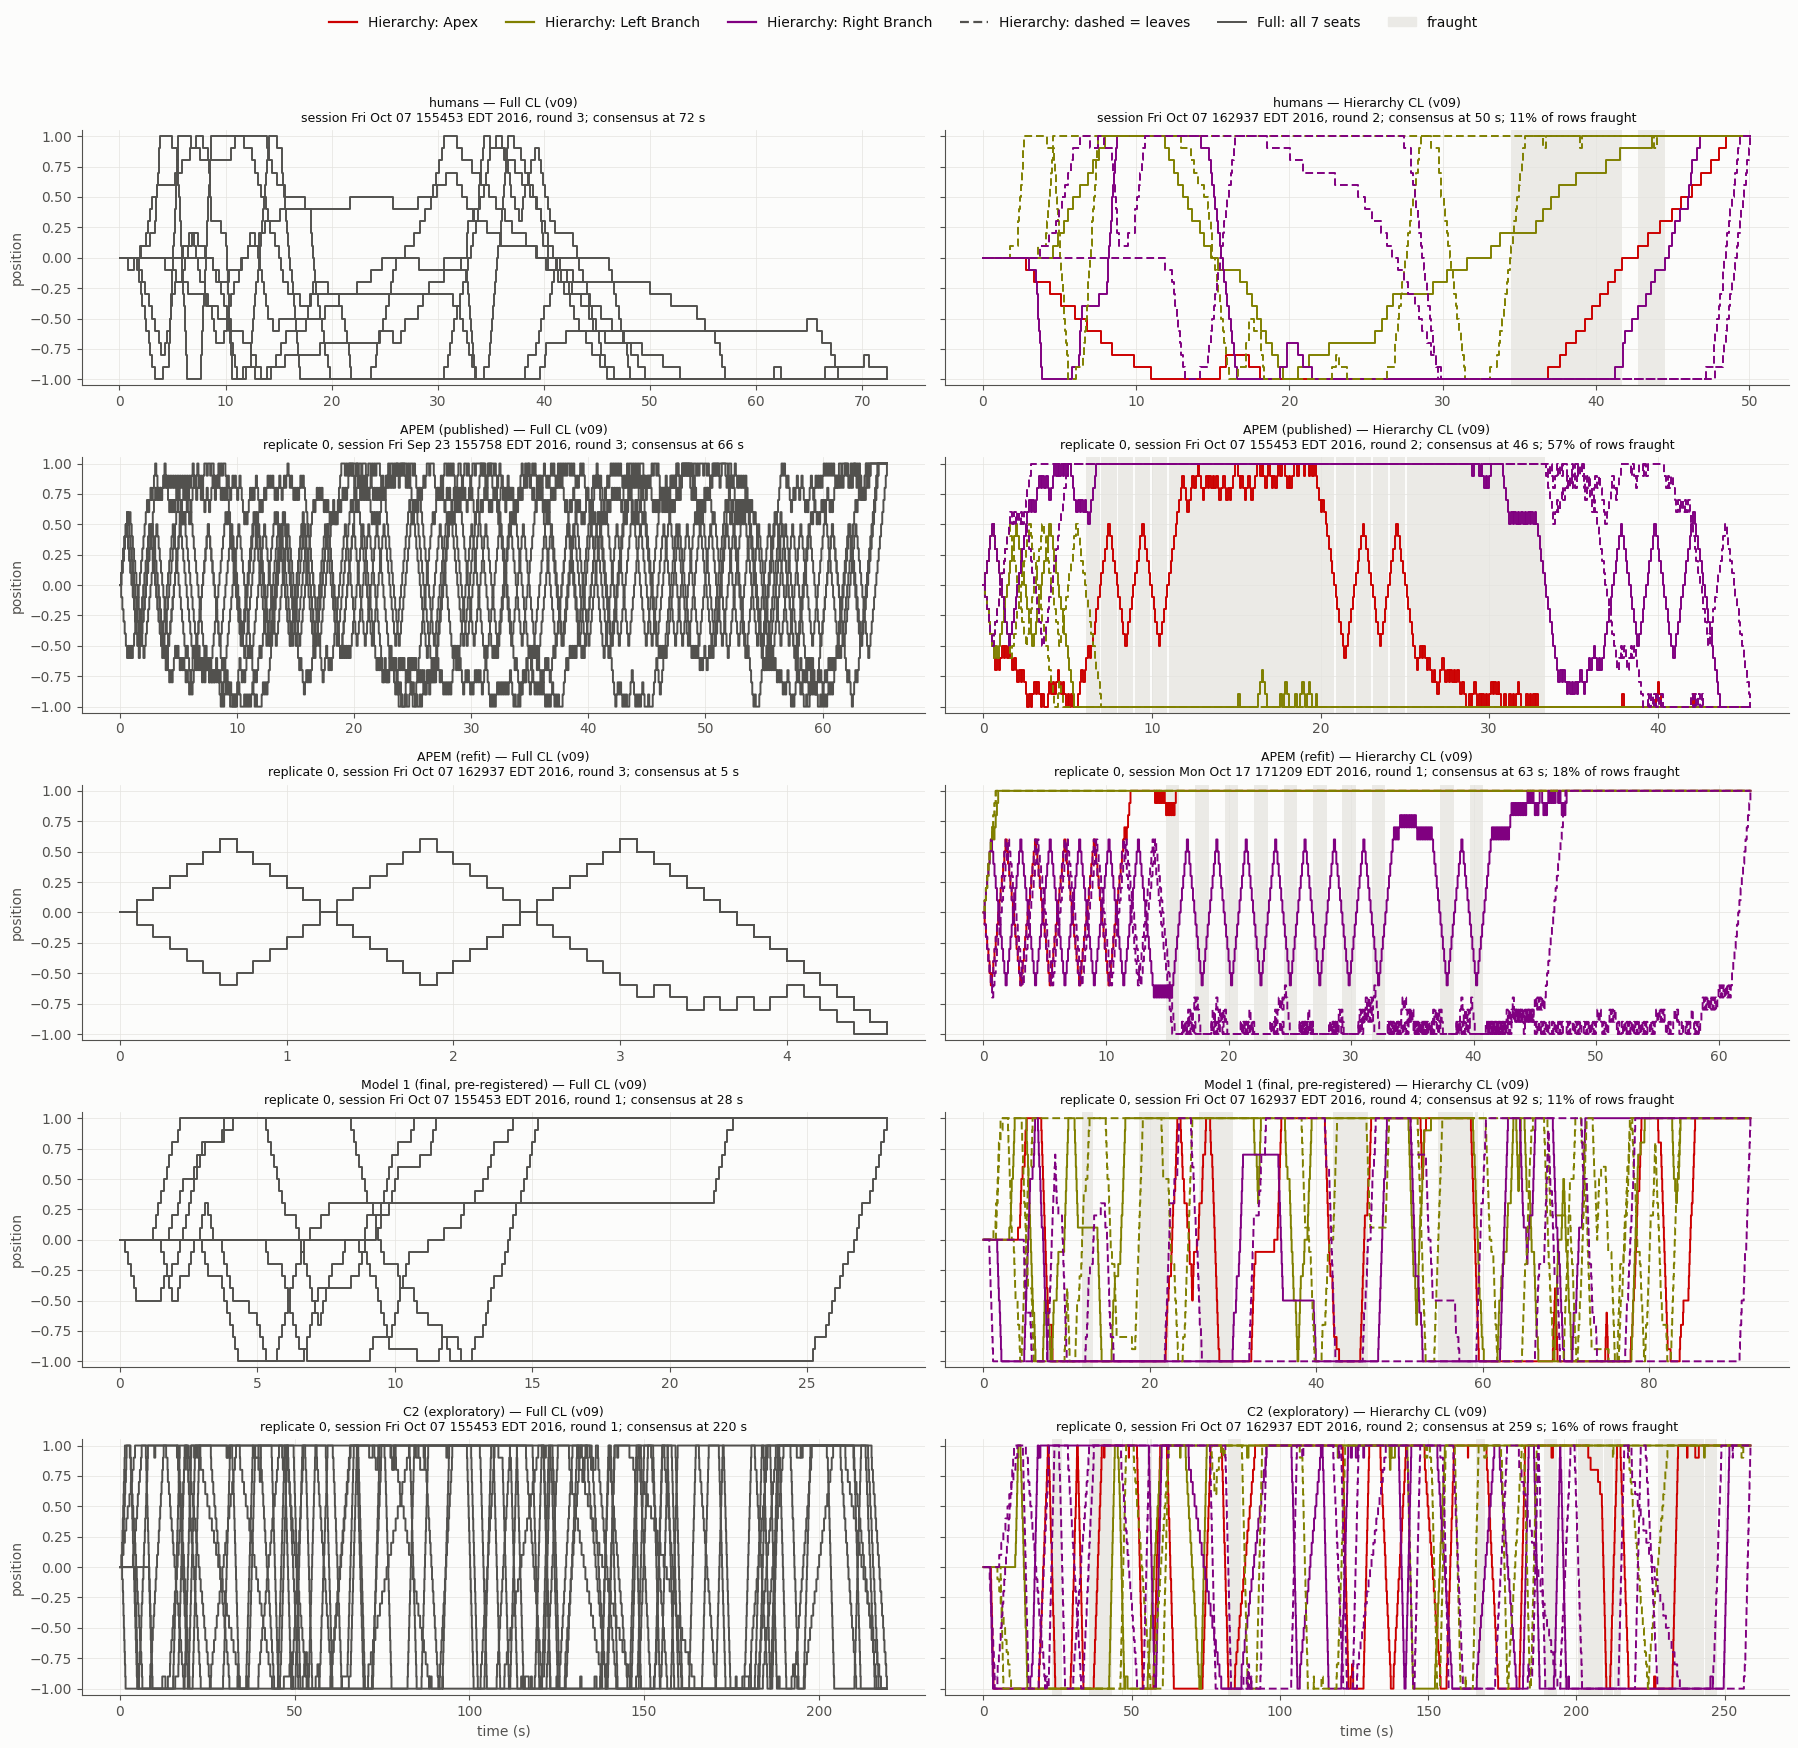

,who,cell,file,wave,success,end (s),replicate
0,humans,Full CL (v09),log_v09_Fri Oct 07 155453 EDT 2016.txt,3,True,72.3,NaN
1,APEM,Full CL (v09),sim0_log_v09_Fri Sep 23 155758 EDT 2016.txt,3,True,65.5,0.0
2,APEMr,Full CL (v09),sim0_log_v09_Fri Oct 07 162937 EDT 2016.txt,3,True,4.6,0.0
3,final,Full CL (v09),sim0_log_v09_Fri Oct 07 155453 EDT 2016.txt,1,True,27.9,0.0
4,C2,Full CL (v09),sim0_log_v09_Fri Oct 07 155453 EDT 2016.txt,1,True,219.5,0.0
5,humans,Hierarchy CL (v09),log_v09_Fri Oct 07 162937 EDT 2016.txt,2,True,50.1,NaN
6,APEM,Hierarchy CL (v09),sim0_log_v09_Fri Oct 07 155453 EDT 2016.txt,2,True,45.5,0.0
7,APEMr,Hierarchy CL (v09),sim0_log_v09_Mon Oct 17 171209 EDT 2016.txt,1,True,62.6,0.0
8,final,Hierarchy CL (v09),sim0_log_v09_Fri Oct 07 162937 EDT 2016.txt,4,True,92.2,0.0
9,C2,Hierarchy CL (v09),sim0_log_v09_Fri Oct 07 162937 EDT 2016.txt,2,True,258.7,0.0


In [13]:
NODE_BRANCH = {0: "Apex", 1: "Left Branch", 3: "Left Branch", 4: "Left Branch",
               2: "Right Branch", 5: "Right Branch", 6: "Right Branch"}
who9 = ["humans", "APEM"] + (["APEMr"] if "APEMr" in TM else []) + ["final", "C2"]
fig, axes = plt.subplots(len(who9), 2, figsize=(18, 3.5 * len(who9)), sharey=True)
picked = []
for j, top in enumerate(["Full", "Hierarchy"]):
    for i, name in enumerate(who9):
        ax = axes[i, j]
        got = src[name]["first"].get((top, "CL"))
        if got is None:
            ax.text(0.5, 0.5, "no qualifying round", transform=ax.transAxes, ha="center", color=INK_2)
            ax.set_title(f"{LABEL[name]} — {top} CL (v09)", fontsize=9.5)
            continue
        run, info = got
        t, x = run["t"], V.node_positions(run, top)
        mask = fraught_mask(run)
        edges = np.append(t, t[-1])
        s0 = None
        for k in range(len(t) + 1):                                     # shade fraught rows (each holds until the next)
            on = k < len(t) and mask[k]
            if on and s0 is None:
                s0 = edges[k]
            if not on and s0 is not None:
                ax.axvspan(s0, edges[k], color=BAND, linewidth=0, zorder=0)
                s0 = None
        for node in range(7):
            colour = BRANCH[NODE_BRANCH[node]] if top == "Hierarchy" else INK_2
            ax.step(t, x[:, node], where="post", color=colour, linewidth=1.4,
                    linestyle="-" if (top == "Full" or node < 3) else (0, (4, 2)))
        where = f"replicate {info['replicate']}, " if "replicate" in info else ""
        fr = 100 * np.mean(mask)
        short = info["file"].split("log_v09_")[-1].replace(".txt", "")
        ax.set_title(f"{LABEL[name]} — {top} CL (v09)\n{where}session {short}, round {info['wave']}; consensus at {t[-1]:.0f} s"
                     + (f"; {fr:.0f}% of rows fraught" if top == "Hierarchy" else ""), fontsize=9)
        picked.append({"who": name, "cell": f"{top} CL (v09)", **info, "end (s)": round(float(t[-1]), 1)})
        ax.set_ylim(-1.05, 1.05)
        ax.grid(color=GRID, linewidth=0.5)
    axes[-1, j].set_xlabel("time (s)")
for ax in axes[:, 0]:
    ax.set_ylabel("position")
handles = [Line2D([], [], color=c, linewidth=1.6, label=f"Hierarchy: {l}") for l, c in BRANCH.items()]
handles += [Line2D([], [], color=INK_2, linewidth=1.6, linestyle=(0, (4, 2)), label="Hierarchy: dashed = leaves"),
            Line2D([], [], color=INK_2, linewidth=1.4, label="Full: all 7 seats"), Patch(color=BAND, label="fraught")]
handles += [Patch(color="none", label=NOTE)] if NOTE else []
fig.legend(handles=handles, loc="upper center", ncol=6, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.955))
fig.savefig(fig_path(9), dpi=150)
plt.show()
pd.DataFrame(picked)

**What it shows.** One round per source and cell: every line is one slider (sign-corrected; ±1 are the two ends), grey
shading marks fraught rows (Full has none by construction). Each is the first qualifying round of the Fig 5 selection
(successful; Hierarchy also > 10% fraught): humans in L3 order, models in replicate then design order; the table lists
which.

## Appendix — all 53 check statistics + 10c

In [14]:
def fv(x, small):
    return "—" if pd.isna(x) else (f"{x:.3f}" if small else f"{x:.2f}")


app = []
for _, r in wide.iterrows():
    small = abs(r["human"]) < 1
    row = {"target": r["target"], "stat": r["stat"] + ("" if r["in_check_list"] else " (10c, not a check)"),
           "cell": f"{r['topology']} {r['dataset']}",
           "human [CI]": f"{fv(r['human'], small)} [{fv(r['ci_lo'], small)}, {fv(r['ci_hi'], small)}]" + (" *" if r["ci_rule"] else "")}
    for m in MODELS:
        row[m] = f"{fv(r[f'sim_{m}'], small)} ({r[f'gap_{m}']:+.2f} {'P' if r[f'pass_{m}'] else 'M'})"
    app.append(row)
print("value (gap in CI half-widths, P = pass / M = miss); * = zero-width CI replaced by the rule; R:", R)
print(pd.DataFrame(app).to_string(index=False))

value (gap in CI half-widths, P = pass / M = miss); * = zero-width CI replaced by the rule; R: {'APEM': 100, 'APEMr': 200, 'C1': 200, 'C2': 200, 'RW': 20, 'final': 200}
 target                               stat         cell               human [CI]                 RW              APEM            APEMr            final               C1               C2
      1                   success_rate_pct      Full CC    97.22 [90.90, 100.00]    0.00 (-21.37 M)  22.44 (-16.44 M) 15.01 (-18.07 M) 46.75 (-11.10 M)  60.25 (-8.13 M)  81.72 (-3.41 M)
      1                   success_rate_pct      Full CL     89.74 [82.05, 97.44]    0.00 (-11.67 M)   19.08 (-9.19 M)  18.40 (-9.28 M)  51.03 (-5.03 M)  53.62 (-4.70 M)  77.73 (-1.56 M)
      1                   success_rate_pct Hierarchy CC    92.50 [84.21, 100.00]    0.00 (-11.72 M)  100.00 (+0.95 P)  64.70 (-3.52 M)  78.42 (-1.78 M)  86.39 (-0.77 P)  93.08 (+0.07 P)
      1                   success_rate_pct Hierarchy CL    97.44 [92.31, 100.00]    0.0

## Caveats

- **Training data, not a test.** Every human value here comes from the train + val run sets the models were built on;
  passes are fit, not prediction.
- **C1 and C2 are exploratory** (results/model_b_log.md entries 2-3), not pre-registered; only Model 1 (final) is.
- **APEM (published)** is the paper's parameter set (a = s = 0.5, mu = 0.1) on our interface. **APEM (refit)** is the
  P26 winner (entry 5): the lowest sum of z² over the 53 check statistics in a two-stage grid search, with mu per part
  (lab / cloud). It minimizes that loss, not the pass count, so it can pass fewer statistics than the published set.
  Its mu_lab (0.05) is the lowest value searched. Figs 4-9 do not include it yet (pending runs).
- **RW is an Agreement-blind null** (flips at every check-in, whatever the neighbours do), with R = 20 and no runs
  beyond the time limit.
- **Old CL is excluded** for humans and every model (entry 4 scope); old-CL rounds are a different interface (0.02 step).
- **Ring and CT are untouched**: never loaded here or in the runs behind it.
- Trajectory figures (5-9) rest on 20 replicates per model; the check statistics on 20-200.

## Summary numbers (fills the Summary cell at the top)

In [15]:
L = []
L.append("**Check statistics (53; inside the human 95% CI):** " + "; ".join(
    f"{LABEL[m]} {score.iloc[i]['passes (of 53)']:.0f} passes, {score.iloc[i][PRIM]:.0f}/{PRIM.split('of ')[1].rstrip(')')} primary, "
    f"median |gap| {score.iloc[i]['median |gap|']:.2f}" + (f" (R = {R[m]})" if m == "RW" else "") for i, m in enumerate(MODELS)) + ".")
L.append("")
L.append("**Humans reach consensus by T in:** " + "; ".join(f"{r['cell']} {r['humans x/y by T']}" for _, r in reach.iterrows()) + ".")
L.append("")
L.append("**Time to the human success level (T × 3 runs; slowdown = model time / human time to the same level):**")
L.append("")
L.append("| cell | human level, time | " + " | ".join(LABEL[m] for m in MODELS) + " |")
L.append("|---|---|" + "---|" * len(MODELS))
for _, r in reach.iterrows():
    cells_ = []
    for m in MODELS:
        t_m = r[f"{m} time to level (s)"]
        if t_m == "pending":
            cells_.append("pending")
        elif isinstance(t_m, str):
            cells_.append(f"{t_m.replace(')', '')}; at T {r[f'{m} share at T']:.2f})" if "share" in t_m
                          else f"{t_m} (share at T {r[f'{m} share at T']:.2f})")
        else:
            cells_.append(f"{t_m:.0f} s, × {r[f'{m} slowdown']:.1f}")
    L.append(f"| {r['cell']} | {r['humans x/y by T']}, {r['human time to that level (s)']:.0f} s | " + " | ".join(cells_) + " |")
L.append("")
tot = ep.groupby(["cell", "who"]).agg(n=("episodes", "sum"), per_round=("per_round", "sum")).reset_index()
L.append("**Stuck episodes per round, all types (C2 vs. humans):** " + "; ".join(
    f"{cname(c)} {tot[(tot['cell'] == cname(c)) & (tot['who'] == 'C2')]['per_round'].iloc[0]:.2f} vs. "
    f"{tot[(tot['cell'] == cname(c)) & (tot['who'] == 'humans')]['per_round'].iloc[0]:.2f}" for c in CELLS) + ".")
text = "\n".join(L)
summary.update(Markdown(text))
print(text)

**Check statistics (53; inside the human 95% CI):** RW (Agreement-blind) 1 passes, 0/21 primary, median |gap| 7.80 (R = 20); APEM (published) 16 passes, 4/21 primary, median |gap| 1.63; APEM (refit) 11 passes, 5/21 primary, median |gap| 2.76; Model 1 (final, pre-registered) 16 passes, 8/21 primary, median |gap| 1.69; C1 (exploratory) 18 passes, 7/21 primary, median |gap| 1.23; C2 (exploratory) 30 passes, 11/21 primary, median |gap| 0.86.

**Humans reach consensus by T in:** Hierarchy EL 48/51 (94.1%); Hierarchy CL (v09) 38/39 (97.4%); Hierarchy CC 37/40 (92.5%); Full CL (v09) 35/39 (89.7%); Full CC 35/36 (97.2%).

**Time to the human success level (T × 3 runs; slowdown = model time / human time to the same level):**

| cell | human level, time | RW (Agreement-blind) | APEM (published) | APEM (refit) | Model 1 (final, pre-registered) | C1 (exploratory) | C2 (exploratory) |
|---|---|---|---|---|---|---|---|
| Hierarchy EL | 48/51 (94.1%), 277 s | not run beyond T (share at T 0.00) | 332 